# VAE vs. DDPM on CIFAR-10 — implemented from scratch

This notebook contains the **complete implementation** of both models. Each code cell in Part 1 writes one
file of the repository (the first line of every file names it) and running them recreates the package on
the Colab machine. Parts 2–3 train and evaluate the models with it.

**How to use**
1. *Runtime → Change runtime type →* **L4** (or A100). Use the same GPU type for every final run.
2. At the start of **every** session, run everything up to Part 2 (*Runtime → Run before* on the Phase 0 cell).
3. Training is **resumable**: runs are stored on Google Drive. After a disconnect, re-run the setup and the
   same training cell; it continues from the last checkpoint (saved every 15 minutes).
4. Colab Pro has no background execution: keep this tab open while training.

*This notebook is generated from the repository by `scripts/build_notebook.py`; edit the repository files, not these cells.*

## 0. Setup

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/vae-vs-ddpm'

import os
os.makedirs(f'{DRIVE}/runs', exist_ok=True)
os.makedirs('/content/repo', exist_ok=True)
%cd /content/repo
!mkdir -p src/genmodels/eval configs scripts
!ln -sfn {DRIVE}/runs runs

name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/repo


# Part 1 — Implementation (from scratch)

### `pyproject.toml`
**Package definition.** Makes `import genmodels` work and lists the dependencies.

In [2]:
%%writefile pyproject.toml
# Repository file: pyproject.toml
[build-system]
requires = ["setuptools>=64"]
build-backend = "setuptools.build_meta"

[project]
name = "genmodels"
version = "0.1.0"
description = "VAE (Kingma & Welling, 2013) and DDPM (Ho et al., 2020) from scratch, benchmarked on CIFAR-10"
requires-python = ">=3.10"
dependencies = ["torch>=2.2", "torchvision", "numpy", "pyyaml", "matplotlib", "tqdm"]

[project.optional-dependencies]
eval = ["torch-fidelity==0.3.0", "scipy"]
dev = ["pytest"]

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]
pythonpath = ["src"]

Writing pyproject.toml


### `src/genmodels/__init__.py`
Package marker.

In [3]:
%%writefile src/genmodels/__init__.py
# Repository file: src/genmodels/__init__.py

Writing src/genmodels/__init__.py


### `src/genmodels/nn_blocks.py`
**Shared building blocks** for both models, following the official DDPM code: a Wide-ResNet residual block (GroupNorm → Swish → conv, with the timestep embedding added in), single-head self-attention, down/up-sampling, the sinusoidal timestep embedding and the paper's weight initialisation.

In [4]:
%%writefile src/genmodels/nn_blocks.py
# Repository file: src/genmodels/nn_blocks.py
"""Building blocks shared by the DDPM U-Net and the convolutional VAE.

The blocks follow the official DDPM implementation (Ho et al., 2020,
github.com/hojonathanho/diffusion, `diffusion_tf/models/unet.py`): a Wide-ResNet
style residual block with GroupNorm + Swish, single-head self-attention, and
TF-style "fan_avg" variance-scaling initialisation (with near-zero init for the
last layer of every residual branch).
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


def default_init_(module: nn.Module, scale: float = 1.0) -> nn.Module:
    """TF `variance_scaling(scale, 'fan_avg', 'uniform')` == Xavier-uniform with gain sqrt(scale)."""
    scale = max(scale, 1e-10)  # the official code uses 1e-10 for "zero" init
    nn.init.xavier_uniform_(module.weight, gain=math.sqrt(scale))
    if module.bias is not None:
        nn.init.zeros_(module.bias)
    return module


def conv3x3(in_ch, out_ch, stride=1, init_scale=1.0):
    return default_init_(nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1), init_scale)


def nin(in_ch, out_ch, init_scale=1.0):
    """Network-in-network == 1x1 convolution."""
    return default_init_(nn.Conv2d(in_ch, out_ch, 1), init_scale)


def linear(in_f, out_f, init_scale=1.0):
    return default_init_(nn.Linear(in_f, out_f), init_scale)


def normalize(ch: int) -> nn.GroupNorm:
    return nn.GroupNorm(num_groups=32, num_channels=ch, eps=1e-6)


def timestep_embedding(t: torch.Tensor, dim: int) -> torch.Tensor:
    """Transformer sinusoidal embedding, as in the official `get_timestep_embedding`."""
    assert dim % 2 == 0
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / (half - 1))
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


class Downsample(nn.Module):
    def __init__(self, ch: int, with_conv: bool = True):
        super().__init__()
        self.with_conv = with_conv
        if with_conv:
            # TF 'SAME' padding for a stride-2 3x3 conv pads (0, 1) on each spatial axis.
            self.conv = default_init_(nn.Conv2d(ch, ch, 3, stride=2, padding=0))

    def forward(self, x):
        if self.with_conv:
            return self.conv(F.pad(x, (0, 1, 0, 1)))
        return F.avg_pool2d(x, 2)


class Upsample(nn.Module):
    def __init__(self, ch: int, with_conv: bool = True):
        super().__init__()
        self.conv = conv3x3(ch, ch) if with_conv else None

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2.0, mode="nearest")
        return self.conv(x) if self.conv is not None else x


class ResnetBlock(nn.Module):
    """GN -> Swish -> conv -> (+ time embedding) -> GN -> Swish -> dropout -> conv, plus skip.

    `temb_ch=0` gives the unconditional variant used by the VAE.
    """

    def __init__(self, in_ch: int, out_ch: int, temb_ch: int = 0, dropout: float = 0.0):
        super().__init__()
        self.norm1 = normalize(in_ch)
        self.conv1 = conv3x3(in_ch, out_ch)
        self.temb_proj = linear(temb_ch, out_ch) if temb_ch > 0 else None
        self.norm2 = normalize(out_ch)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = conv3x3(out_ch, out_ch, init_scale=0.0)
        self.skip = nin(in_ch, out_ch) if in_ch != out_ch else nn.Identity()

    def forward(self, x, temb=None):
        h = self.conv1(F.silu(self.norm1(x)))
        if self.temb_proj is not None:
            h = h + self.temb_proj(F.silu(temb))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return self.skip(x) + h


class AttnBlock(nn.Module):
    """Single-head spatial self-attention with a residual connection."""

    def __init__(self, ch: int):
        super().__init__()
        self.norm = normalize(ch)
        self.q, self.k, self.v = nin(ch, ch), nin(ch, ch), nin(ch, ch)
        self.proj_out = nin(ch, ch, init_scale=0.0)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        q = self.q(h).reshape(B, C, H * W).transpose(1, 2)  # B, HW, C
        k = self.k(h).reshape(B, C, H * W).transpose(1, 2)
        v = self.v(h).reshape(B, C, H * W).transpose(1, 2)
        # Same maths as softmax(q k^T / sqrt(C)) v, using the fused kernel when available.
        h = F.scaled_dot_product_attention(q[:, None], k[:, None], v[:, None])[:, 0]
        h = h.transpose(1, 2).reshape(B, C, H, W)
        return x + self.proj_out(h)

Writing src/genmodels/nn_blocks.py


### `src/genmodels/unet.py`
**DDPM noise-prediction network ε_θ(x_t, t)** — Ho et al. (2020), Appendix B: a PixelCNN++-style U-Net with four resolutions (32→4), two residual blocks per resolution and self-attention at 16×16. 35.7M parameters, as in the paper.

In [5]:
%%writefile src/genmodels/unet.py
# Repository file: src/genmodels/unet.py
"""DDPM noise-prediction U-Net (Ho et al., 2020, Appendix B).

PixelCNN++-style U-Net on a Wide-ResNet backbone with GroupNorm, four feature-map
resolutions (32x32 -> 4x4), two residual blocks per resolution, self-attention at
16x16 and a sinusoidal timestep embedding added into every residual block. With the
CIFAR-10 settings (ch=128, ch_mult=(1, 2, 2, 2)) it has 35.7M parameters, matching
the paper.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

from .nn_blocks import (AttnBlock, Downsample, ResnetBlock, Upsample, conv3x3,
                        linear, normalize, timestep_embedding)


class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=3, ch=128, ch_mult=(1, 2, 2, 2), num_res_blocks=2,
                 attn_resolutions=(16,), dropout=0.1, resamp_with_conv=True, resolution=32):
        super().__init__()
        self.ch = ch
        temb_ch = ch * 4
        self.temb = nn.Sequential(linear(ch, temb_ch), nn.SiLU(), linear(temb_ch, temb_ch))
        self.conv_in = conv3x3(in_ch, ch)

        # Downsampling path; `skip_chs` records the channels of every stored activation.
        self.down = nn.ModuleList()
        skip_chs, cur_ch, res = [ch], ch, resolution
        for level, mult in enumerate(ch_mult):
            blocks, attns = nn.ModuleList(), nn.ModuleList()
            for _ in range(num_res_blocks):
                blocks.append(ResnetBlock(cur_ch, ch * mult, temb_ch, dropout))
                cur_ch = ch * mult
                attns.append(AttnBlock(cur_ch) if res in attn_resolutions else nn.Identity())
                skip_chs.append(cur_ch)
            stage = nn.Module()
            stage.blocks, stage.attns = blocks, attns
            if level != len(ch_mult) - 1:
                stage.downsample = Downsample(cur_ch, resamp_with_conv)
                skip_chs.append(cur_ch)
                res //= 2
            self.down.append(stage)

        self.mid_block1 = ResnetBlock(cur_ch, cur_ch, temb_ch, dropout)
        self.mid_attn = AttnBlock(cur_ch)
        self.mid_block2 = ResnetBlock(cur_ch, cur_ch, temb_ch, dropout)

        # Upsampling path: num_res_blocks + 1 blocks per level, each consuming one skip.
        self.up = nn.ModuleList()
        for level, mult in reversed(list(enumerate(ch_mult))):
            blocks, attns = nn.ModuleList(), nn.ModuleList()
            for _ in range(num_res_blocks + 1):
                blocks.append(ResnetBlock(cur_ch + skip_chs.pop(), ch * mult, temb_ch, dropout))
                cur_ch = ch * mult
                attns.append(AttnBlock(cur_ch) if res in attn_resolutions else nn.Identity())
            stage = nn.Module()
            stage.blocks, stage.attns = blocks, attns
            if level != 0:
                stage.upsample = Upsample(cur_ch, resamp_with_conv)
                res *= 2
            self.up.insert(0, stage)
        assert not skip_chs

        self.norm_out = normalize(cur_ch)
        self.conv_out = conv3x3(cur_ch, out_ch, init_scale=0.0)

    def forward(self, x, t):
        temb = self.temb(timestep_embedding(t, self.ch))
        hs = [self.conv_in(x)]
        for stage in self.down:
            for block, attn in zip(stage.blocks, stage.attns):
                hs.append(attn(block(hs[-1], temb)))
            if hasattr(stage, "downsample"):
                hs.append(stage.downsample(hs[-1]))

        h = self.mid_block2(self.mid_attn(self.mid_block1(hs[-1], temb)), temb)

        for stage in reversed(self.up):
            for block, attn in zip(stage.blocks, stage.attns):
                h = attn(block(torch.cat([h, hs.pop()], dim=1), temb))
            if hasattr(stage, "upsample"):
                h = stage.upsample(h)
        assert not hs
        return self.conv_out(F.silu(self.norm_out(h)))

Writing src/genmodels/unet.py


### `src/genmodels/diffusion.py`
**The diffusion process** — Ho et al. (2020):
* forward process `q_sample`: x_t = √ᾱ_t · x_0 + √(1−ᾱ_t) · ε, with the linear β schedule 1e-4 → 0.02, T = 1000;
* training loss `training_loss`: L_simple = ‖ε − ε_θ(x_t, t)‖² (Algorithm 1);
* sampling `p_sample_loop`: 1000 ancestral steps (Algorithm 2), plus DDIM (`ddim_sample_loop`) for fast sampling with the same trained network;
* likelihood `calc_bpd`: the full variational bound in bits/dim (paper eq. 5, discretised decoder).

In [6]:
%%writefile src/genmodels/diffusion.py
# Repository file: src/genmodels/diffusion.py
"""Gaussian diffusion process of Ho et al. (2020).

Forward process q(x_t | x_0) with a fixed linear beta schedule, training with
L_simple (epsilon prediction), ancestral sampling (Algorithm 2), deterministic DDIM
sampling (Song et al., 2021, applied post hoc to the same network) and the full
variational bound in bits/dim (Section 3.3 + Appendix, discretised Gaussian decoder).
All schedule constants are computed in float64 and stored as float32 buffers.
"""
import math

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from .unet import UNet


def get_beta_schedule(name: str, T: int, beta_start: float = 1e-4, beta_end: float = 0.02) -> np.ndarray:
    if name == "linear":
        return np.linspace(beta_start, beta_end, T, dtype=np.float64)
    raise ValueError(f"unknown beta schedule {name!r}")


def _extract(a: torch.Tensor, t: torch.Tensor, ndim: int) -> torch.Tensor:
    """a[t] reshaped to broadcast against a tensor with `ndim` dims."""
    return a.gather(0, t).reshape(-1, *([1] * (ndim - 1)))


def normal_kl(mean1, logvar1, mean2, logvar2):
    """KL(N(mean1, exp(logvar1)) || N(mean2, exp(logvar2))), elementwise, in nats."""
    return 0.5 * (-1.0 + logvar2 - logvar1 + torch.exp(logvar1 - logvar2)
                  + (mean1 - mean2) ** 2 * torch.exp(-logvar2))


def _approx_std_normal_cdf(x):
    return 0.5 * (1.0 + torch.tanh(math.sqrt(2.0 / math.pi) * (x + 0.044715 * x ** 3)))


def discretized_gaussian_log_likelihood(x, means, log_scales):
    """log p(x) for x on the 256-level grid in [-1, 1] (bin half-width 1/255), as in the official code."""
    centered = x - means
    inv_stdv = torch.exp(-log_scales)
    cdf_plus = _approx_std_normal_cdf(inv_stdv * (centered + 1.0 / 255.0))
    cdf_min = _approx_std_normal_cdf(inv_stdv * (centered - 1.0 / 255.0))
    log_cdf_plus = torch.log(cdf_plus.clamp(min=1e-12))
    log_one_minus_cdf_min = torch.log((1.0 - cdf_min).clamp(min=1e-12))
    log_cdf_delta = torch.log((cdf_plus - cdf_min).clamp(min=1e-12))
    return torch.where(x < -0.999, log_cdf_plus,
                       torch.where(x > 0.999, log_one_minus_cdf_min, log_cdf_delta))


def _mean_flat(x):
    return x.mean(dim=tuple(range(1, x.ndim)))


class GaussianDiffusion(nn.Module):
    """Holds the fixed forward-process constants (buffers only, no parameters)."""

    def __init__(self, betas: np.ndarray, model_var_type: str = "fixedlarge", clip_denoised: bool = True):
        super().__init__()
        self.T = len(betas)
        self.model_var_type = model_var_type
        self.clip_denoised = clip_denoised

        alphas = 1.0 - betas
        ac = np.cumprod(alphas)
        ac_prev = np.append(1.0, ac[:-1])
        post_var = betas * (1.0 - ac_prev) / (1.0 - ac)
        consts = {
            "betas": betas,
            "alphas_cumprod": ac,
            "alphas_cumprod_prev": ac_prev,
            "sqrt_alphas_cumprod": np.sqrt(ac),
            "sqrt_one_minus_alphas_cumprod": np.sqrt(1.0 - ac),
            "sqrt_recip_alphas_cumprod": np.sqrt(1.0 / ac),
            "sqrt_recipm1_alphas_cumprod": np.sqrt(1.0 / ac - 1.0),
            "posterior_variance": post_var,
            # posterior variance is 0 at t=0, so the log is clipped to its t=1 value
            "posterior_log_variance_clipped": np.log(np.append(post_var[1], post_var[1:])),
            "posterior_mean_coef1": betas * np.sqrt(ac_prev) / (1.0 - ac),
            "posterior_mean_coef2": (1.0 - ac_prev) * np.sqrt(alphas) / (1.0 - ac),
            # sigma_t^2 = beta_t ("fixedlarge", used for CIFAR-10) or beta~_t ("fixedsmall")
            "logvar_fixedlarge": np.log(np.append(post_var[1], betas[1:])),
            "logvar_fixedsmall": np.log(np.append(post_var[1], post_var[1:])),
        }
        for name, value in consts.items():
            self.register_buffer(name, torch.tensor(value, dtype=torch.float32), persistent=False)

    # ---- forward process -------------------------------------------------------------
    def q_sample(self, x0, t, noise):
        return (_extract(self.sqrt_alphas_cumprod, t, x0.ndim) * x0
                + _extract(self.sqrt_one_minus_alphas_cumprod, t, x0.ndim) * noise)

    def q_posterior(self, x0, xt, t):
        mean = (_extract(self.posterior_mean_coef1, t, xt.ndim) * x0
                + _extract(self.posterior_mean_coef2, t, xt.ndim) * xt)
        return mean, _extract(self.posterior_log_variance_clipped, t, xt.ndim)

    def predict_x0_from_eps(self, xt, t, eps):
        return (_extract(self.sqrt_recip_alphas_cumprod, t, xt.ndim) * xt
                - _extract(self.sqrt_recipm1_alphas_cumprod, t, xt.ndim) * eps)

    # ---- reverse process -------------------------------------------------------------
    def p_mean_variance(self, model, xt, t, var_type=None):
        eps = model(xt, t).float()
        x0 = self.predict_x0_from_eps(xt, t, eps)
        if self.clip_denoised:
            x0 = x0.clamp(-1.0, 1.0)
        mean, _ = self.q_posterior(x0, xt, t)
        logvar = _extract(getattr(self, f"logvar_{var_type or self.model_var_type}"), t, xt.ndim)
        return mean, logvar, x0

    def training_loss(self, model, x0, generator=None):
        """L_simple: E_{t, eps} || eps - eps_theta(sqrt(a_bar) x0 + sqrt(1 - a_bar) eps, t) ||^2."""
        B = x0.shape[0]
        t = torch.randint(0, self.T, (B,), device=x0.device, generator=generator)
        noise = torch.randn(x0.shape, device=x0.device, generator=generator)
        eps = model(self.q_sample(x0, t, noise), t)
        return F.mse_loss(eps.float(), noise)

    @torch.no_grad()
    def p_sample_loop(self, model, shape, generator=None, device="cuda", progress=None, record_steps=()):
        """Algorithm 2 of the paper: T ancestral steps (no noise at the final step).

        With `record_steps`, also returns {t: (x_t, predicted x_0)} for those timesteps.
        """
        x = torch.randn(shape, device=device, generator=generator)
        trajectory = {}
        steps = range(self.T - 1, -1, -1)
        for i in (progress(steps) if progress else steps):
            t = torch.full((shape[0],), i, device=device, dtype=torch.long)
            mean, logvar, pred_x0 = self.p_mean_variance(model, x, t)
            if i in record_steps:
                trajectory[i] = (x.float().cpu(), pred_x0.float().cpu())
            if i > 0:
                x = mean + torch.exp(0.5 * logvar) * torch.randn(shape, device=device, generator=generator)
            else:
                x = mean
        return (x, trajectory) if record_steps else x

    def ddim_timesteps(self, num_steps: int):
        """Uniform sub-sequence of timesteps, as in the DDIM paper's CIFAR-10 setting."""
        skip = self.T // num_steps
        return list(range(0, self.T, skip))[:num_steps]

    @torch.no_grad()
    def ddim_sample_loop(self, model, shape, num_steps=100, eta=0.0, generator=None, device="cuda", progress=None,
                         x_T=None):
        """Deterministic for eta = 0: the sample is a fixed function of the starting noise x_T."""
        x = torch.randn(shape, device=device, generator=generator) if x_T is None else x_T
        seq = self.ddim_timesteps(num_steps)
        seq_prev = [-1] + seq[:-1]
        pairs = list(zip(reversed(seq), reversed(seq_prev)))
        for i, j in (progress(pairs) if progress else pairs):
            t = torch.full((shape[0],), i, device=device, dtype=torch.long)
            ab = self.alphas_cumprod[i]
            ab_prev = self.alphas_cumprod[j] if j >= 0 else torch.ones((), device=device)
            eps = model(x, t).float()
            x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()
            if self.clip_denoised:
                x0 = x0.clamp(-1.0, 1.0)
                eps = (x - ab.sqrt() * x0) / (1 - ab).sqrt()  # keep eps consistent with the clipped x0
            sigma = eta * ((1 - ab_prev) / (1 - ab) * (1 - ab / ab_prev)).sqrt()
            x = ab_prev.sqrt() * x0 + (1 - ab_prev - sigma ** 2).clamp(min=0).sqrt() * eps
            if eta > 0 and j >= 0:
                x = x + sigma * torch.randn(shape, device=device, generator=generator)
        return x

    # ---- likelihood ------------------------------------------------------------------
    @torch.no_grad()
    def calc_bpd(self, model, x0, var_types=("fixedlarge",), generator=None, progress=None):
        """Variational bound -log p(x0) <= L_T + sum_{t>1} L_{t-1} + L_0, in bits/dim, per image.

        One forward pass per timestep serves every requested reverse-process variance, since
        they share the predicted mean. Returns {var_type: {"total", "prior", "terms"}}.
        """
        B, T = x0.shape[0], self.T
        terms = {v: torch.zeros(B, T, device=x0.device) for v in var_types}
        steps = range(T - 1, -1, -1)
        for i in (progress(steps) if progress else steps):
            t = torch.full((B,), i, device=x0.device, dtype=torch.long)
            noise = torch.randn(x0.shape, device=x0.device, generator=generator)
            xt = self.q_sample(x0, t, noise)
            true_mean, true_logvar = self.q_posterior(x0, xt, t)
            eps = model(xt, t).float()
            pred_x0 = self.predict_x0_from_eps(xt, t, eps)
            if self.clip_denoised:
                pred_x0 = pred_x0.clamp(-1.0, 1.0)
            model_mean, _ = self.q_posterior(pred_x0, xt, t)
            for v in var_types:
                model_logvar = _extract(getattr(self, f"logvar_{v}"), t, xt.ndim)
                if i == 0:
                    nll = -discretized_gaussian_log_likelihood(x0, model_mean, 0.5 * model_logvar)
                    terms[v][:, i] = _mean_flat(nll) / math.log(2.0)
                else:
                    kl = normal_kl(true_mean, true_logvar, model_mean, model_logvar)
                    terms[v][:, i] = _mean_flat(kl) / math.log(2.0)
        tT = torch.full((B,), T - 1, device=x0.device, dtype=torch.long)
        qT_mean = _extract(self.sqrt_alphas_cumprod, tT, x0.ndim) * x0
        qT_logvar = torch.log(_extract(1.0 - self.alphas_cumprod, tT, x0.ndim))
        prior = _mean_flat(normal_kl(qT_mean, qT_logvar, torch.zeros_like(x0), torch.zeros_like(x0))) / math.log(2.0)
        return {v: {"total": terms[v].sum(1) + prior, "prior": prior, "terms": terms[v]} for v in var_types}


class DDPM(nn.Module):
    """U-Net + diffusion process, operating on uint8 images (scaled to [-1, 1])."""

    def __init__(self, unet: dict, diffusion: dict):
        super().__init__()
        self.net = UNet(**unet)
        self.in_ch, self.resolution = self.net.conv_in.in_channels, unet.get("resolution", 32)
        betas = get_beta_schedule(diffusion.get("beta_schedule", "linear"), diffusion.get("T", 1000),
                                  diffusion.get("beta_start", 1e-4), diffusion.get("beta_end", 0.02))
        self.diffusion = GaussianDiffusion(betas, diffusion.get("model_var_type", "fixedlarge"),
                                           diffusion.get("clip_denoised", True))

    @staticmethod
    def preprocess(x_uint8):
        return x_uint8.float() / 127.5 - 1.0

    def forward(self, x_uint8):
        """Training loss for a batch of uint8 images; returns a dict with key 'loss'."""
        return {"loss": self.diffusion.training_loss(self.net, self.preprocess(x_uint8))}

    @torch.no_grad()
    def eval_metrics(self, x_uint8, generator):
        """L_simple on held-out images with fixed (t, noise), for overfitting checks."""
        return {"test_loss": self.diffusion.training_loss(self.net, self.preprocess(x_uint8), generator).item()}

    @torch.no_grad()
    def sample(self, n, sampler="ddpm", steps=None, generator=None, device="cuda", progress=None, eta=0.0):
        shape = (n, self.in_ch, self.resolution, self.resolution)
        if sampler == "ddpm":
            return self.diffusion.p_sample_loop(self.net, shape, generator, device, progress)
        if sampler == "ddim":
            return self.diffusion.ddim_sample_loop(self.net, shape, steps or 100, eta, generator, device, progress)
        raise ValueError(sampler)

Writing src/genmodels/diffusion.py


### `src/genmodels/vae.py`
**The VAE** — Kingma & Welling (2013): Gaussian encoder q(z|x), reparameterisation z = μ + σ·ε, prior N(0, I), analytic KL (paper eq. 10), Gaussian decoder p(x|z) with learned variance, one sample per image. `MLPVAE` is the paper's own network; `ConvVAE` is the same method with a convolutional network of the U-Net's size, used for the main comparison.

In [7]:
%%writefile src/genmodels/vae.py
# Repository file: src/genmodels/vae.py
"""Variational Autoencoder (Kingma & Welling, 2013 -- Auto-Encoding Variational Bayes).

Method exactly as in the paper (Sections 2.3-2.4, Appendix B/C.2):
  * Gaussian encoder q(z|x) = N(mu(x), diag sigma^2(x)), reparameterised z = mu + sigma * eps,
  * prior p(z) = N(0, I) with the KL term computed analytically (paper eq. 10),
  * Gaussian decoder p(x|z) = N(mu(z), diag sigma^2(z)) for real-valued data,
  * one Monte-Carlo sample per datapoint (L = 1), ELBO summed over all dimensions (beta = 1).

Two networks implement the same method:
  * `MLPVAE`  -- the paper's network: one tanh hidden layer per side (500 units), N(0, 0.01) init.
  * `ConvVAE` -- the same method with a convolutional encoder/decoder built from the DDPM
                 U-Net's blocks, so the VAE-vs-DDPM comparison is not an MLP-vs-U-Net one.

Pixels are uniformly dequantised before training/evaluation, which makes the Gaussian density on
continuous values a valid bound on the discrete likelihood (reported in bits/dim, comparable to
the DDPM's variational bound).
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

from .nn_blocks import (AttnBlock, Downsample, ResnetBlock, Upsample, conv3x3,
                        linear, normalize)

LOG_2PI = math.log(2.0 * math.pi)


class GaussianVAE(nn.Module):
    latent_dim: int
    dec_logvar_min: float

    # --- implemented by subclasses ---------------------------------------------------------
    def encode(self, x):  # -> (mu, logvar) of q(z|x), each (B, latent_dim)
        raise NotImplementedError

    def decoder_raw(self, z):  # -> (mean, raw_logvar) of p(x|z), each (B, C, H, W)
        raise NotImplementedError

    # --- shared method ---------------------------------------------------------------------
    def decode(self, z):
        mean, raw = self.decoder_raw(z)
        # Soft lower bound on the decoder log-variance for numerical safety. The bound sits at the
        # variance of the dequantisation noise itself, below which no real gain in likelihood exists.
        lo = self.dec_logvar_min
        return mean.float(), lo + F.softplus(raw.float() - lo)

    @staticmethod
    def dequantize(x_uint8, generator=None):
        """uint8 pixel k -> (k + u) / 128 - 1, u ~ U[0, 1): a continuous value inside k's bin in [-1, 1)."""
        u = torch.rand(x_uint8.shape, device=x_uint8.device, generator=generator)
        return (x_uint8.float() + u) / 128.0 - 1.0

    @staticmethod
    def bin_centres(x_uint8):
        return (x_uint8.float() + 0.5) / 128.0 - 1.0

    def neg_elbo(self, x, generator=None):
        """Per-image -ELBO = E_q[-log p(x|z)] + KL(q(z|x) || N(0, I)), in nats, summed over dims."""
        mu, logvar = self.encode(x)
        mu, logvar = mu.float(), logvar.float().clamp(-30.0, 20.0)
        eps = torch.randn(mu.shape, device=mu.device, generator=generator)
        z = mu + torch.exp(0.5 * logvar) * eps
        x_mean, x_logvar = self.decode(z)
        recon = 0.5 * (x_logvar + LOG_2PI + (x - x_mean) ** 2 * torch.exp(-x_logvar)).flatten(1).sum(1)
        kl = 0.5 * (mu ** 2 + torch.exp(logvar) - logvar - 1.0).sum(1)
        return {"neg_elbo": recon + kl, "recon": recon, "kl": kl, "mu": mu}

    @staticmethod
    def nats_to_bpd(neg_elbo_nats, num_dims):
        """Continuous density on [-1, 1] with 256 bins of width 2/256 -> discrete NLL bound in bits/dim."""
        return (neg_elbo_nats + num_dims * math.log(128.0)) / (num_dims * math.log(2.0))

    def forward(self, x_uint8):
        x = self.dequantize(x_uint8)
        out = self.neg_elbo(x)
        D = x[0].numel()
        # Both terms are per-image sums divided by the same D: the per-dim scaling does not change
        # the relative weight of reconstruction vs. KL (beta stays exactly 1).
        return {"loss": out["neg_elbo"].mean() / D,
                "recon_per_dim": (out["recon"].mean() / D).detach(),
                "kl_per_dim": (out["kl"].mean() / D).detach()}

    @torch.no_grad()
    def eval_metrics(self, x_uint8, generator):
        x = self.dequantize(x_uint8, generator)
        out = self.neg_elbo(x, generator)
        D = x[0].numel()
        # Active units (Burda et al., 2016): latent dims whose posterior mean varies across data.
        active = (out["mu"].var(0) > 0.01).sum().item()
        return {"test_bpd": self.nats_to_bpd(out["neg_elbo"], D).mean().item(),
                "test_kl_nats": out["kl"].mean().item(),
                "active_units": active}

    @torch.no_grad()
    def sample(self, n, generator=None, device="cuda", **_):
        """Ancestral sample z ~ N(0, I) -> decoder mean (pixel noise is not added, as is standard)."""
        z = torch.randn((n, self.latent_dim), device=device, generator=generator)
        return self.decode(z)[0].clamp(-1.0, 1.0)

    @torch.no_grad()
    def reconstruct(self, x_uint8):
        mu, _ = self.encode(self.bin_centres(x_uint8))
        return self.decode(mu.float())[0].clamp(-1.0, 1.0)


class MLPVAE(GaussianVAE):
    """The paper's network (Appendix C): x -> tanh(500) -> (mu, logvar); z -> tanh(500) -> (mean, logvar)."""

    def __init__(self, img_shape=(3, 32, 32), hidden=500, latent_dim=200, init_std=0.01, dec_logvar_min=-12.0):
        super().__init__()
        self.img_shape, self.latent_dim, self.dec_logvar_min = tuple(img_shape), latent_dim, dec_logvar_min
        D = math.prod(self.img_shape)
        self.enc_h, self.enc_out = nn.Linear(D, hidden), nn.Linear(hidden, 2 * latent_dim)
        self.dec_h, self.dec_out = nn.Linear(latent_dim, hidden), nn.Linear(hidden, 2 * D)
        for p in self.parameters():  # "initialized by random sampling from N(0, 0.01)"
            nn.init.normal_(p, 0.0, init_std)

    def encode(self, x):
        return self.enc_out(torch.tanh(self.enc_h(x.flatten(1)))).chunk(2, dim=1)

    def decoder_raw(self, z):
        mean, logvar = self.dec_out(torch.tanh(self.dec_h(z))).chunk(2, dim=1)
        # Paper: means constrained with a sigmoid; 2*sigmoid - 1 is the same constraint on [-1, 1].
        mean = 2.0 * torch.sigmoid(mean) - 1.0
        return mean.view(-1, *self.img_shape), logvar.view(-1, *self.img_shape)


class ConvVAE(GaussianVAE):
    """Same VAE method, with an encoder mirroring the U-Net's downsampling path and a decoder
    mirroring its upsampling path (same ResNet/attention blocks, no skip connections)."""

    def __init__(self, in_ch=3, ch=128, ch_mult=(1, 2, 2, 2), num_res_blocks=2, attn_resolutions=(16,),
                 latent_dim=128, dropout=0.0, resamp_with_conv=True, resolution=32, dec_logvar_min=-12.0):
        super().__init__()
        self.latent_dim, self.dec_logvar_min = latent_dim, dec_logvar_min
        self.in_ch = in_ch

        def attn(c, r):
            return AttnBlock(c) if r in attn_resolutions else nn.Identity()

        # Encoder: 32x32 -> 4x4
        enc, cur, res = [conv3x3(in_ch, ch)], ch, resolution
        for level, mult in enumerate(ch_mult):
            for _ in range(num_res_blocks):
                enc += [ResnetBlock(cur, ch * mult, dropout=dropout), attn(ch * mult, res)]
                cur = ch * mult
            if level != len(ch_mult) - 1:
                enc.append(Downsample(cur, resamp_with_conv))
                res //= 2
        enc += [ResnetBlock(cur, cur, dropout=dropout), AttnBlock(cur), ResnetBlock(cur, cur, dropout=dropout),
                normalize(cur), nn.SiLU(), nn.Flatten()]
        self.encoder = nn.Sequential(*enc)
        self.enc_out = linear(cur * res * res, 2 * latent_dim)

        # Decoder: 4x4 -> 32x32
        self.bottleneck = (cur, res)
        self.dec_in = linear(latent_dim, cur * res * res)
        dec = [ResnetBlock(cur, cur, dropout=dropout), AttnBlock(cur), ResnetBlock(cur, cur, dropout=dropout)]
        for level, mult in reversed(list(enumerate(ch_mult))):
            for _ in range(num_res_blocks + 1):
                dec += [ResnetBlock(cur, ch * mult, dropout=dropout), attn(ch * mult, res)]
                cur = ch * mult
            if level != 0:
                dec.append(Upsample(cur, resamp_with_conv))
                res *= 2
        dec += [normalize(cur), nn.SiLU(), conv3x3(cur, 2 * in_ch, init_scale=0.0)]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x):
        return self.enc_out(self.encoder(x)).chunk(2, dim=1)

    def decoder_raw(self, z):
        c, r = self.bottleneck
        out = self.decoder(self.dec_in(z).view(-1, c, r, r))
        return out[:, :self.in_ch], out[:, self.in_ch:]

Writing src/genmodels/vae.py


### `src/genmodels/models.py`
**Model registry**: builds a model from the `model` section of a config.

In [8]:
%%writefile src/genmodels/models.py
# Repository file: src/genmodels/models.py
"""Model registry: builds a model from the `model` section of a config."""
from .diffusion import DDPM
from .vae import ConvVAE, MLPVAE

REGISTRY = {"ddpm": DDPM, "conv_vae": ConvVAE, "mlp_vae": MLPVAE}


def build_model(model_cfg: dict):
    cfg = dict(model_cfg)
    return REGISTRY[cfg.pop("type")](**cfg)


def network(model):
    """The neural network inside a model (what gets torch.compile'd)."""
    return model.net if hasattr(model, "net") else model

Writing src/genmodels/models.py


### `src/genmodels/data.py`
**Data**: CIFAR-10 kept on the GPU, with shuffling that is a pure function of the step, so a resumed run sees exactly the same batches as an uninterrupted one.

In [9]:
%%writefile src/genmodels/data.py
# Repository file: src/genmodels/data.py
"""CIFAR-10 kept entirely on the GPU as uint8 (150 MB), with deterministic, resumable shuffling.

Batch `step` is a pure function of (seed, step): epoch e uses a permutation seeded by (seed, e)
and the flip mask is seeded by (seed, step). A run resumed from a checkpoint therefore sees exactly
the batches it would have seen without the interruption, and no DataLoader workers are needed.
"""
import numpy as np
import torch
from torchvision.datasets import CIFAR10


def load_cifar10(root: str = "data", train: bool = True):
    """Returns (images uint8 [N, 3, 32, 32], labels int64 [N])."""
    ds = CIFAR10(root=root, train=train, download=True)
    images = torch.from_numpy(np.ascontiguousarray(ds.data)).permute(0, 3, 1, 2).contiguous()
    return images, torch.tensor(ds.targets, dtype=torch.long)


class GPUBatcher:
    def __init__(self, images: torch.Tensor, batch_size: int, seed: int = 0, hflip: bool = True, device="cuda"):
        self.images = images.to(device)
        self.batch_size, self.seed, self.hflip, self.device = batch_size, seed, hflip, device
        self.steps_per_epoch = len(images) // batch_size  # drop the last partial batch
        self._epoch, self._perm = None, None

    def _permutation(self, epoch):
        if epoch != self._epoch:
            g = torch.Generator().manual_seed(self.seed * 1_000_003 + epoch)
            self._perm = torch.randperm(len(self.images), generator=g).to(self.device)
            self._epoch = epoch
        return self._perm

    def batch(self, step: int) -> torch.Tensor:
        epoch, i = divmod(step, self.steps_per_epoch)
        idx = self._permutation(epoch)[i * self.batch_size:(i + 1) * self.batch_size]
        x = self.images[idx]
        if self.hflip:
            g = torch.Generator().manual_seed(self.seed * 7_919 + step)
            flip = (torch.rand(len(idx), generator=g) < 0.5).to(self.device)
            x = torch.where(flip[:, None, None, None], x.flip(3), x)
        return x

Writing src/genmodels/data.py


### `src/genmodels/ema.py`
**EMA** of the weights (decay 0.9999 in the paper); samples come from the EMA model.

In [10]:
%%writefile src/genmodels/ema.py
# Repository file: src/genmodels/ema.py
"""Exponential moving average of model weights (DDPM uses decay 0.9999, no warm-up)."""
import copy

import torch
import torch.nn as nn


class EMA:
    def __init__(self, model: nn.Module, decay: float):
        self.decay = decay
        self.model = copy.deepcopy(model).eval().requires_grad_(False)

    @torch.no_grad()
    def update(self, model: nn.Module):
        ema_p = list(self.model.parameters())
        cur_p = [p.detach() for p in model.parameters()]
        torch._foreach_lerp_(ema_p, cur_p, 1.0 - self.decay)
        for eb, b in zip(self.model.buffers(), model.buffers()):
            eb.copy_(b)

    def state_dict(self):
        return self.model.state_dict()

    def load_state_dict(self, state):
        self.model.load_state_dict(state)

Writing src/genmodels/ema.py


### `src/genmodels/utils.py`
**Utilities**: configs, seeding, crash-safe saving, precision choice, image grids.

In [11]:
%%writefile src/genmodels/utils.py
# Repository file: src/genmodels/utils.py
import os
import random
from pathlib import Path

import numpy as np
import torch
import yaml


def load_config(path, overrides=()):
    """Load a YAML config and apply `a.b.c=value` overrides (values parsed as YAML)."""
    with open(path) as f:
        cfg = yaml.safe_load(f)
    for item in overrides:
        key, value = item.split("=", 1)
        node = cfg
        *parents, leaf = key.split(".")
        for p in parents:
            node = node.setdefault(p, {})
        node[leaf] = yaml.safe_load(value)
    return cfg


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def atomic_save(obj, path):
    """Write to a temp file then rename, so a disconnect mid-write never corrupts the checkpoint."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def autocast_dtype(precision: str, device: torch.device):
    """'auto' -> bf16 on Ampere or newer (A100, L4), else fp32. fp16 is not used (unstable for diffusion)."""
    if device.type != "cuda" or precision == "fp32":
        return None
    if precision == "bf16" or (precision == "auto" and torch.cuda.get_device_capability(device)[0] >= 8):
        return torch.bfloat16
    return None


def to_uint8(x: torch.Tensor) -> torch.Tensor:
    """[-1, 1] float images -> uint8 in [0, 255] (same quantisation as the official DDPM code)."""
    return ((x.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)


def save_grid(x: torch.Tensor, path, nrow=8):
    from torchvision.utils import save_image
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    save_image(to_uint8(x).float() / 255.0, path, nrow=nrow, padding=2)

Writing src/genmodels/utils.py


### `src/genmodels/trainer.py`
**Training loop** shared by every model: bf16 mixed precision, learning-rate warm-up, gradient clipping, EMA, periodic evaluation / sample grids / snapshots, and checkpoints every 15 minutes for resuming after a Colab disconnect.

In [12]:
%%writefile src/genmodels/trainer.py
# Repository file: src/genmodels/trainer.py
"""One training loop for every model: mixed precision, EMA, warm-up, gradient clipping,
periodic evaluation / sample grids / EMA snapshots, and crash-safe resumable checkpoints.

Everything a run produces lives in `run_dir`:
  config.yaml        resolved config
  metrics.jsonl      one JSON object per log / eval event
  samples/           EMA sample grids during training (fixed noise, so progress is comparable)
  snapshots/         EMA weights every `snapshot_every` steps (for FID-vs-training-step curves)
  ckpt_last.pt       full resumable state (model, EMA, optimiser, RNG, step, GPU-seconds)
  ema_final.pt       final EMA weights + bookkeeping, used for evaluation
"""
import json
import math
import time
from pathlib import Path

import torch
import yaml

from .data import GPUBatcher
from .ema import EMA
from .models import build_model, network
from .utils import atomic_save, autocast_dtype, save_grid, seed_everything


def make_optimizer(model, ocfg, num_train, num_dims):
    params = model.parameters()
    name = ocfg["name"]
    if name == "adam":
        return torch.optim.Adam(params, lr=ocfg["lr"], betas=tuple(ocfg.get("betas", (0.9, 0.999))),
                                eps=ocfg.get("eps", 1e-8), weight_decay=ocfg.get("weight_decay", 0.0))
    if name == "adagrad":
        wd = ocfg.get("weight_decay", 0.0)
        if wd == "prior":
            # Kingma & Welling: MAP with p(theta) = N(0, I). Our loss is the per-dim mean of the
            # per-image -ELBO, so the prior's gradient theta / N becomes theta / (N * D).
            wd = 1.0 / (num_train * num_dims)
        return torch.optim.Adagrad(params, lr=ocfg["lr"], weight_decay=wd)
    raise ValueError(f"unknown optimiser {name!r}")


def train(cfg, run_dir, train_images, test_images, device=None, max_steps=None, log=print):
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    run_dir = Path(run_dir)
    (run_dir / "samples").mkdir(parents=True, exist_ok=True)
    (run_dir / "snapshots").mkdir(exist_ok=True)
    tcfg = cfg["train"]
    seed_everything(cfg.get("seed", 0))

    model = build_model(cfg["model"]).to(device)
    ema = EMA(model, tcfg["ema_decay"])
    opt = make_optimizer(model, tcfg["optim"], len(train_images), train_images[0].numel())
    batcher = GPUBatcher(train_images, tcfg["batch_size"], cfg.get("seed", 0), cfg["data"].get("hflip", True), device)
    test_x = test_images[:tcfg.get("eval_images", 2000)].to(device)

    step, train_seconds, gpus = 0, 0.0, []
    ckpt_path = run_dir / "ckpt_last.pt"
    if ckpt_path.exists():
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        ema.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["opt"])
        step, train_seconds, gpus = ck["step"], ck["train_seconds"], ck["gpus"]
        # map_location moved every tensor to `device`; RNG states must be CPU ByteTensors
        torch.set_rng_state(ck["rng_cpu"].cpu())
        if device.type == "cuda" and ck.get("rng_cuda") is not None:
            torch.cuda.set_rng_state(ck["rng_cuda"].cpu(), device)
        if ck["cfg"]["model"] != cfg["model"]:
            raise RuntimeError("model config differs from the checkpoint's; refusing to resume")
        log(f"resumed from step {step} ({train_seconds / 3600:.2f} GPU-h so far)")
    else:
        with open(run_dir / "config.yaml", "w") as f:
            yaml.safe_dump(cfg, f, sort_keys=False)
    gpu_name = torch.cuda.get_device_name(device) if device.type == "cuda" else "cpu"
    if gpu_name not in gpus:
        gpus.append(gpu_name)

    if tcfg.get("compile", False):
        network(model).compile()
    dtype = autocast_dtype(tcfg.get("precision", "auto"), device)
    total = max_steps or tcfg["total_steps"]
    n_params = sum(p.numel() for p in model.parameters())
    log(f"{cfg['name']}: {n_params / 1e6:.2f}M params | {gpu_name} | autocast={dtype} | steps {step} -> {total}")

    metrics_f = open(run_dir / "metrics.jsonl", "a")

    def emit(row):
        metrics_f.write(json.dumps(row) + "\n")
        metrics_f.flush()

    def sync():
        if device.type == "cuda":
            torch.cuda.synchronize(device)

    def save_ckpt():
        atomic_save({"model": model.state_dict(), "ema": ema.state_dict(), "opt": opt.state_dict(),
                     "step": step, "train_seconds": train_seconds, "gpus": gpus, "cfg": cfg,
                     "rng_cpu": torch.get_rng_state(),
                     "rng_cuda": torch.cuda.get_rng_state(device) if device.type == "cuda" else None},
                    ckpt_path)

    def autocast():
        return torch.autocast(device.type, dtype=dtype or torch.float32, enabled=dtype is not None)

    base_lr, warmup = tcfg["optim"]["lr"], tcfg.get("warmup_steps", 0)
    sample_gen_seed = 12345  # fixed noise for the progress grids
    win_t0, win_steps, loss_acc, extra_acc, acc_n = time.perf_counter(), 0, None, {}, 0
    last_ckpt = time.time()

    def close_window():
        """Account wall time spent in training steps since the window opened."""
        nonlocal train_seconds, win_t0, win_steps
        sync()
        dt = time.perf_counter() - win_t0
        train_seconds += dt
        its = win_steps / dt if dt > 0 else 0.0
        win_t0, win_steps = time.perf_counter(), 0
        return its

    model.train()
    while step < total:
        x = batcher.batch(step)
        lr = base_lr * min(1.0, (step + 1) / warmup) if warmup else base_lr
        for g in opt.param_groups:
            g["lr"] = lr
        with autocast():
            out = model(x)
        loss = out["loss"]
        opt.zero_grad(set_to_none=True)
        loss.backward()
        gnorm = (torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg["grad_clip"])
                 if tcfg.get("grad_clip") else None)
        opt.step()
        ema.update(model)
        step += 1
        win_steps += 1
        loss_acc = loss.detach() if loss_acc is None else loss_acc + loss.detach()
        acc_n += 1
        for k, v in out.items():
            if k != "loss":
                extra_acc[k] = extra_acc.get(k, 0.0) + v

        if step % tcfg.get("log_every", 100) == 0 or step == total:
            n = acc_n
            mean_loss = (loss_acc / n).item()
            if not math.isfinite(mean_loss):
                raise FloatingPointError(f"non-finite loss at step {step}; last checkpoint is kept")
            its = close_window()
            row = {"step": step, "loss": mean_loss, "lr": lr, "it_s": its, "gpu_h": train_seconds / 3600,
                   **{k: (v / n).item() if torch.is_tensor(v) else v / n for k, v in extra_acc.items()}}
            if gnorm is not None:
                row["grad_norm"] = gnorm.item()
            if device.type == "cuda":
                row["mem_gb"] = torch.cuda.max_memory_allocated(device) / 1e9
            emit(row)
            log(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))
            loss_acc, extra_acc, acc_n = None, {}, 0

        eval_now = step % tcfg.get("eval_every", 5000) == 0 or step == total
        sample_now = step % tcfg.get("sample_every", 5000) == 0 or step == total
        snap_now = step % tcfg.get("snapshot_every", 10000) == 0
        ckpt_now = time.time() - last_ckpt > 60 * tcfg.get("ckpt_every_minutes", 15) or step == total
        if eval_now or sample_now or snap_now or ckpt_now:
            close_window()
            if eval_now:
                g = torch.Generator(device).manual_seed(0)
                model.eval()
                with autocast():
                    row = {"step": step, **{f"raw_{k}": v for k, v in model.eval_metrics(test_x, g).items()}}
                    g.manual_seed(0)
                    row.update({f"ema_{k}": v for k, v in ema.model.eval_metrics(test_x, g).items()})
                model.train()
                emit(row)
                log(f"eval @ {step}: " + ", ".join(f"{k}={v:.4g}" for k, v in row.items() if k != "step"))
            if sample_now:
                g = torch.Generator(device).manual_seed(sample_gen_seed)
                with autocast():
                    imgs = ema.model.sample(64, sampler="ddim", steps=100, generator=g, device=device)
                save_grid(imgs.float(), run_dir / "samples" / f"step_{step:07d}.png")
            if snap_now:
                atomic_save({"ema": ema.state_dict(), "step": step}, run_dir / "snapshots" / f"ema_{step:07d}.pt")
            if ckpt_now:
                save_ckpt()
                last_ckpt = time.time()
            win_t0 = time.perf_counter()  # time spent above is not training time

    atomic_save({"ema": ema.state_dict(), "model": model.state_dict(), "step": step, "cfg": cfg,
                 "train_seconds": train_seconds, "gpus": gpus, "n_params": n_params},
                run_dir / "ema_final.pt")
    metrics_f.close()
    log(f"done: {step} steps, {train_seconds / 3600:.2f} GPU-h on {gpus}")
    return model, ema

Writing src/genmodels/trainer.py


### `configs/ddpm_cifar10.yaml`
**DDPM hyper-parameters** (paper values, with sources).

In [13]:
%%writefile configs/ddpm_cifar10.yaml
# Repository file: configs/ddpm_cifar10.yaml
# DDPM, CIFAR-10 -- Ho et al. (2020), Appendix B, and the official code's CIFAR-10 settings.
# The only deviation from the paper is the training length (paper: 800k steps on a TPU v3-8).
name: ddpm_cifar10
seed: 0
data:
  dataset: cifar10
  hflip: true                    # "random horizontal flips ... improve sample quality slightly"
model:
  type: ddpm
  unet:
    ch: 128
    ch_mult: [1, 2, 2, 2]        # four resolutions, 32x32 -> 4x4
    num_res_blocks: 2
    attn_resolutions: [16]       # self-attention at 16x16
    dropout: 0.1                 # swept over {0.1, 0.2, 0.3, 0.4} in the paper
    resamp_with_conv: true
  diffusion:
    T: 1000
    beta_schedule: linear
    beta_start: 1.0e-4
    beta_end: 0.02
    model_var_type: fixedlarge   # sigma_t^2 = beta_t (official CIFAR-10 setting)
    clip_denoised: true
train:
  batch_size: 128
  total_steps: 150000            # paper: 800k; final value set by the Phase-0 calibration
  optim: {name: adam, lr: 2.0e-4, betas: [0.9, 0.999], eps: 1.0e-8, weight_decay: 0.0}
  warmup_steps: 5000             # official code
  grad_clip: 1.0                 # official code
  ema_decay: 0.9999
  precision: auto                # bf16 on A100 / L4, fp32 otherwise
  compile: false
  log_every: 100
  eval_every: 5000
  sample_every: 5000
  snapshot_every: 10000
  ckpt_every_minutes: 15
  eval_images: 2000

Writing configs/ddpm_cifar10.yaml


### `configs/vae_conv_cifar10.yaml`
**Convolutional VAE hyper-parameters** (matched to the DDPM run).

In [14]:
%%writefile configs/vae_conv_cifar10.yaml
# Repository file: configs/vae_conv_cifar10.yaml
# VAE, CIFAR-10 -- Kingma & Welling (2013) method (Gaussian encoder, reparameterisation,
# N(0, I) prior, analytic KL, Gaussian decoder with learned variance, L = 1, beta = 1) with a
# convolutional encoder/decoder built from the same blocks and widths as the DDPM U-Net.
# Data, augmentation, batch size, optimiser, EMA and precision match the DDPM run.
name: vae_conv_cifar10
seed: 0
data:
  dataset: cifar10
  hflip: true
model:
  type: conv_vae
  ch: 128
  ch_mult: [1, 2, 2, 2]
  num_res_blocks: 2
  attn_resolutions: [16]
  latent_dim: 128
  dropout: 0.0
  resamp_with_conv: true
  dec_logvar_min: -12.0
train:
  batch_size: 128
  total_steps: 60000             # ~150 epochs; test bound tracked every eval for overfitting
  optim: {name: adam, lr: 2.0e-4, betas: [0.9, 0.999], eps: 1.0e-8, weight_decay: 0.0}
  warmup_steps: 5000
  grad_clip: 1.0
  ema_decay: 0.9999
  precision: auto
  compile: false
  log_every: 100
  eval_every: 2500
  sample_every: 5000
  snapshot_every: 10000
  ckpt_every_minutes: 15
  eval_images: 2000

Writing configs/vae_conv_cifar10.yaml


### `configs/vae_mlp_cifar10.yaml`
**Paper MLP VAE hyper-parameters** (Kingma & Welling's own settings).

In [15]:
%%writefile configs/vae_mlp_cifar10.yaml
# Repository file: configs/vae_mlp_cifar10.yaml
# VAE with the paper's own network (Kingma & Welling, 2013, Section 5 / Appendix C):
# one tanh hidden layer of 500 units per side, Gaussian decoder (means constrained by a sigmoid),
# N(0, 0.01) init, Adagrad with global step size from {0.01, 0.02, 0.1}, minibatches of M = 100,
# L = 1, and a weight-decay term from the prior p(theta) = N(0, I). No data augmentation.
# Only the data differ: 3072-dim colour CIFAR-10 instead of MNIST / Frey Face.
name: vae_mlp_cifar10
seed: 0
data:
  dataset: cifar10
  hflip: false
model:
  type: mlp_vae
  img_shape: [3, 32, 32]
  hidden: 500
  latent_dim: 200                # the largest latent size in the paper's experiments
  init_std: 0.01
  dec_logvar_min: -12.0
train:
  batch_size: 100
  total_steps: 500000            # 1000 epochs (the paper trained for ~10^8 samples)
  optim: {name: adagrad, lr: 0.02, weight_decay: prior}
  warmup_steps: 0
  grad_clip: null
  ema_decay: 0.9999
  precision: fp32
  compile: false
  log_every: 1000
  eval_every: 25000
  sample_every: 50000
  snapshot_every: 100000
  ckpt_every_minutes: 15
  eval_images: 2000

Writing configs/vae_mlp_cifar10.yaml


### `scripts/train.py`
**Training script**: train or resume a run from a config.

In [16]:
%%writefile scripts/train.py
# Repository file: scripts/train.py
"""Train a model from a config. Re-running the same command resumes from `<run-dir>/ckpt_last.pt`.

    python scripts/train.py --config configs/ddpm_cifar10.yaml --run-dir runs/ddpm_cifar10
    python scripts/train.py --config configs/vae_conv_cifar10.yaml --set train.total_steps=50000
"""
import argparse
from pathlib import Path

from genmodels.data import load_cifar10
from genmodels.trainer import train
from genmodels.utils import load_config


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--run-dir", default=None, help="default: runs/<config name>")
    ap.add_argument("--data-root", default="data")
    ap.add_argument("--set", nargs="*", default=[], help="config overrides, e.g. train.total_steps=1000")
    ap.add_argument("--max-steps", type=int, default=None, help="stop early (smoke tests); total_steps is unchanged")
    args = ap.parse_args()

    cfg = load_config(args.config, args.set)
    run_dir = Path(args.run_dir or Path("runs") / cfg["name"])
    train_x, _ = load_cifar10(args.data_root, train=True)
    test_x, _ = load_cifar10(args.data_root, train=False)
    train(cfg, run_dir, train_x, test_x, max_steps=args.max_steps)


if __name__ == "__main__":
    main()

Writing scripts/train.py


### `scripts/benchmark.py`
**Calibration script**: measures speed on this GPU and projects the cost of the plan.

In [17]:
%%writefile scripts/benchmark.py
# Repository file: scripts/benchmark.py
"""Phase-0 calibration: measure training speed and sampling throughput on this GPU and project
the GPU-hours / Colab compute units of the full plan. Uses random data (no dataset download).

    python scripts/benchmark.py --units-per-hour 1.7
"""
import argparse
import time

import torch

from genmodels.data import GPUBatcher
from genmodels.models import build_model, network
from genmodels.trainer import make_optimizer
from genmodels.utils import autocast_dtype, load_config

DEFAULT_CONFIGS = ["configs/ddpm_cifar10.yaml", "configs/vae_conv_cifar10.yaml"]
EVAL_NFE = 22e6  # network evaluations needed by the DDPM evaluation protocol (README, "Evaluation")


def bench_train(cfg, device, steps, warmup, compile_):
    tcfg = cfg["train"]
    model = build_model(cfg["model"]).to(device)
    if compile_:
        network(model).compile()
    opt = make_optimizer(model, tcfg["optim"], 50000, 3072)
    data = torch.randint(0, 256, (4096, 3, 32, 32), dtype=torch.uint8)
    batcher = GPUBatcher(data, tcfg["batch_size"], device=device)
    dtype = autocast_dtype(tcfg.get("precision", "auto"), device)
    torch.cuda.reset_peak_memory_stats(device)
    for i in range(warmup + steps):
        if i == warmup:
            torch.cuda.synchronize(device)
            t0 = time.perf_counter()
        with torch.autocast("cuda", dtype=dtype or torch.float32, enabled=dtype is not None):
            loss = model(batcher.batch(i))["loss"]
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
    torch.cuda.synchronize(device)
    its = steps / (time.perf_counter() - t0)
    return model, dtype, its, torch.cuda.max_memory_allocated(device) / 1e9


@torch.no_grad()
def bench_nfe(model, dtype, device, batch, reps=10):
    """Network evaluations (one image through the U-Net once) per second."""
    net = network(model).eval()
    x = torch.randn(batch, 3, 32, 32, device=device)
    t = torch.randint(0, 1000, (batch,), device=device)
    with torch.autocast("cuda", dtype=dtype or torch.float32, enabled=dtype is not None):
        for _ in range(3):
            net(x, t)
        torch.cuda.synchronize(device)
        t0 = time.perf_counter()
        for _ in range(reps):
            net(x, t)
        torch.cuda.synchronize(device)
    return batch * reps / (time.perf_counter() - t0)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--configs", nargs="*", default=DEFAULT_CONFIGS)
    ap.add_argument("--steps", type=int, default=50)
    ap.add_argument("--warmup", type=int, default=15)
    ap.add_argument("--compile", action="store_true")
    ap.add_argument("--sample-batch", type=int, default=500)
    ap.add_argument("--units-per-hour", type=float, default=None,
                    help="the rate Colab shows for this GPU (Runtime > View resources)")
    ap.add_argument("--batch-sizes", type=int, nargs="*", default=None,
                    help="only measure training throughput (images/s) of the first config at these batch sizes")
    args = ap.parse_args()

    device = torch.device("cuda")
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = True
    print(f"GPU: {torch.cuda.get_device_name(device)} | compile={args.compile}\n")
    if args.batch_sizes:
        # Training speed is images/s, not steps/s: a bigger batch only helps if images/s rises.
        base = None
        for bs in args.batch_sizes:
            cfg = load_config(args.configs[0], [f"train.batch_size={bs}"])
            model, _, its, mem = bench_train(cfg, device, args.steps, args.warmup, args.compile)
            base = base or its * bs
            print(f"{cfg['name']:<20} batch {bs:4d}: {its:6.2f} it/s = {its * bs:7.0f} images/s "
                  f"({its * bs / base:4.2f}x the first batch size) | peak {mem:5.1f} GB")
            del model
            torch.cuda.empty_cache()
        return
    total_h = 0.0
    for path in args.configs:
        cfg = load_config(path)
        model, dtype, its, mem = bench_train(cfg, device, args.steps, args.warmup, args.compile)
        hours = cfg["train"]["total_steps"] / its / 3600
        total_h += hours
        print(f"{cfg['name']:<20} {its:6.2f} it/s | peak {mem:5.1f} GB | autocast {dtype} | "
              f"{cfg['train']['total_steps']} steps -> {hours:5.2f} h")
        if cfg["model"]["type"] == "ddpm":
            nfe = bench_nfe(model, dtype, device, args.sample_batch)
            eval_h = EVAL_NFE / nfe / 3600
            total_h += eval_h
            print(f"{'':<20} sampling {nfe:,.0f} NFE/s | 1000-step sampling of 10k images: "
                  f"{1e7 / nfe / 3600:.2f} h | full eval protocol ({EVAL_NFE / 1e6:.0f}M NFE): {eval_h:.2f} h")
        del model
        torch.cuda.empty_cache()
    print(f"\nprojected total (training + DDPM evaluation): {total_h:.1f} GPU-h", end="")
    if args.units_per_hour:
        print(f" ~= {total_h * args.units_per_hour:.0f} compute units at {args.units_per_hour}/h")
    else:
        print("  (pass --units-per-hour to convert to compute units)")


if __name__ == "__main__":
    main()

Writing scripts/benchmark.py


### Install the package and load CIFAR-10

In [18]:
!pip install -q -e ".[eval]"

# `pip install -e` is only picked up by Python processes started afterwards (the `!python ...` commands).
# This notebook's own process was already running, so add the source folder to its import path directly.
import sys, importlib
if '/content/repo/src' not in sys.path:
    sys.path.insert(0, '/content/repo/src')
importlib.invalidate_caches()

# Cache the CIFAR-10 archive on Drive so later sessions skip the download
!mkdir -p data && if [ -f {DRIVE}/cifar-10-python.tar.gz ]; then cp {DRIVE}/cifar-10-python.tar.gz data/; fi
!python -c "from genmodels.data import load_cifar10; load_cifar10('data'); load_cifar10('data', train=False)"
!if [ ! -f {DRIVE}/cifar-10-python.tar.gz ]; then cp data/cifar-10-python.tar.gz {DRIVE}/; fi

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for genmodels (pyproject.toml) ... done


### Quick check of the implementation

In [19]:
import torch
from genmodels.models import build_model
from genmodels.utils import load_config

for name in ['ddpm_cifar10', 'vae_conv_cifar10', 'vae_mlp_cifar10']:
    model = build_model(load_config(f'configs/{name}.yaml')['model'])
    print(f'{name:<18} {sum(p.numel() for p in model.parameters()) / 1e6:6.2f}M parameters')

ddpm_cifar10        35.75M parameters
vae_conv_cifar10    30.37M parameters
vae_mlp_cifar10      4.92M parameters


# Part 2 — Training

## Phase 0 — calibration (≈10 min)
Read this GPU's compute-unit rate from *Runtime → View resources* and enter it below. The benchmark measures
training speed and sampling throughput and projects the total cost of the plan. It runs with and without
`--compile`; use compile for training only if it is clearly faster.

In [20]:
UNITS_PER_HOUR = 1.7   # <- replace with the rate Colab shows
!python scripts/benchmark.py --units-per-hour {UNITS_PER_HOUR}
!python scripts/benchmark.py --units-per-hour {UNITS_PER_HOUR} --compile

GPU: NVIDIA A100-SXM4-80GB | compile=False

ddpm_cifar10          10.63 it/s | peak   6.6 GB | autocast torch.bfloat16 | 150000 steps ->  3.92 h
                     sampling 4,565 NFE/s | 1000-step sampling of 10k images: 0.61 h | full eval protocol (22M NFE): 1.34 h
vae_conv_cifar10      12.71 it/s | peak   5.3 GB | autocast torch.bfloat16 | 60000 steps ->  1.31 h

projected total (training + DDPM evaluation): 6.6 GPU-h ~= 11 compute units at 1.7/h
GPU: NVIDIA A100-SXM4-80GB | compile=True

ddpm_cifar10          16.07 it/s | peak   3.3 GB | autocast torch.bfloat16 | 150000 steps ->  2.59 h
                     sampling 8,702 NFE/s | 1000-step sampling of 10k images: 0.32 h | full eval protocol (22M NFE): 0.70 h
vae_conv_cifar10      19.26 it/s | peak   2.7 GB | autocast torch.bfloat16 | 60000 steps ->  0.87 h

projected total (training + DDPM evaluation): 4.2 GPU-h ~= 7 compute units at 1.7/h


## Phase 1 — VAE with the paper's own network (MLP)
Small model (4.9M parameters): about 20–40 minutes, under 1 compute unit.

In [21]:
!python scripts/train.py --config configs/vae_mlp_cifar10.yaml --run-dir runs/vae_mlp_cifar10

resumed from step 500000 (0.44 GPU-h so far)
vae_mlp_cifar10: 4.92M params | NVIDIA A100-SXM4-80GB | autocast=None | steps 500000 -> 500000
done: 500000 steps, 0.44 GPU-h on ['NVIDIA A100-SXM4-80GB']


## Phase 2 — VAE (convolutional network, Kingma & Welling method)

In [22]:
COMPILE = 'false'   # 'true' if the benchmark showed a clear speed-up
!python scripts/train.py --config configs/vae_conv_cifar10.yaml --run-dir runs/vae_conv_cifar10 --set train.compile={COMPILE}

vae_conv_cifar10: 30.37M params | NVIDIA A100-SXM4-80GB | autocast=torch.bfloat16 | steps 0 -> 60000
step 100 | loss 1.042 | lr 4e-06 | it_s 5.914 | gpu_h 0.004697 | recon_per_dim 1.034 | kl_per_dim 0.007873 | grad_norm 4.697 | mem_gb 5.538
step 200 | loss 0.9443 | lr 8e-06 | it_s 12.63 | gpu_h 0.006896 | recon_per_dim 0.9416 | kl_per_dim 0.00275 | grad_norm 4.473 | mem_gb 5.538
step 300 | loss 0.7652 | lr 1.2e-05 | it_s 12.64 | gpu_h 0.009094 | recon_per_dim 0.7565 | kl_per_dim 0.008668 | grad_norm 4.499 | mem_gb 5.538
step 400 | loss 0.5138 | lr 1.6e-05 | it_s 12.65 | gpu_h 0.01129 | recon_per_dim 0.4954 | kl_per_dim 0.01841 | grad_norm 5.174 | mem_gb 5.538
step 500 | loss 0.2427 | lr 2e-05 | it_s 12.66 | gpu_h 0.01348 | recon_per_dim 0.2124 | kl_per_dim 0.03029 | grad_norm 17.89 | mem_gb 5.538
step 600 | loss 0.1153 | lr 2.4e-05 | it_s 12.6 | gpu_h 0.01569 | recon_per_dim 0.07451 | kl_per_dim 0.04076 | grad_norm 6.239 | mem_gb 5.538
step 700 | loss 0.06247 | lr 2.8e-05 | it_s 12.66 

## Phase 3 — DDPM (Ho et al., 2020)
`DDPM_STEPS` is set from the calibration (paper: 800k). It can be raised later and the run resumed; the model
config itself must not change between sessions (the trainer refuses to resume if it does).

In [23]:
DDPM_STEPS = 150000
!python scripts/train.py --config configs/ddpm_cifar10.yaml --run-dir runs/ddpm_cifar10 --set train.total_steps={DDPM_STEPS} train.compile={COMPILE}

ddpm_cifar10: 35.75M params | NVIDIA A100-SXM4-80GB | autocast=torch.bfloat16 | steps 0 -> 150000
step 100 | loss 0.9884 | lr 4e-06 | it_s 4.474 | gpu_h 0.006209 | grad_norm 3.426 | mem_gb 6.876
step 200 | loss 0.8945 | lr 8e-06 | it_s 10.6 | gpu_h 0.008831 | grad_norm 3.277 | mem_gb 6.876
step 300 | loss 0.708 | lr 1.2e-05 | it_s 10.58 | gpu_h 0.01145 | grad_norm 2.89 | mem_gb 6.876
step 400 | loss 0.4795 | lr 1.6e-05 | it_s 10.6 | gpu_h 0.01408 | grad_norm 2.287 | mem_gb 6.876
step 500 | loss 0.2593 | lr 2e-05 | it_s 10.57 | gpu_h 0.0167 | grad_norm 1.458 | mem_gb 6.876
step 600 | loss 0.1037 | lr 2.4e-05 | it_s 10.6 | gpu_h 0.01932 | grad_norm 0.5618 | mem_gb 6.876
step 700 | loss 0.04974 | lr 2.8e-05 | it_s 10.6 | gpu_h 0.02195 | grad_norm 0.3411 | mem_gb 6.876
step 800 | loss 0.04277 | lr 3.2e-05 | it_s 10.58 | gpu_h 0.02457 | grad_norm 0.2801 | mem_gb 6.876
step 900 | loss 0.04097 | lr 3.6e-05 | it_s 10.57 | gpu_h 0.0272 | grad_norm 0.2352 | mem_gb 6.876
step 1000 | loss 0.04058 

## Progress monitor (run any time)

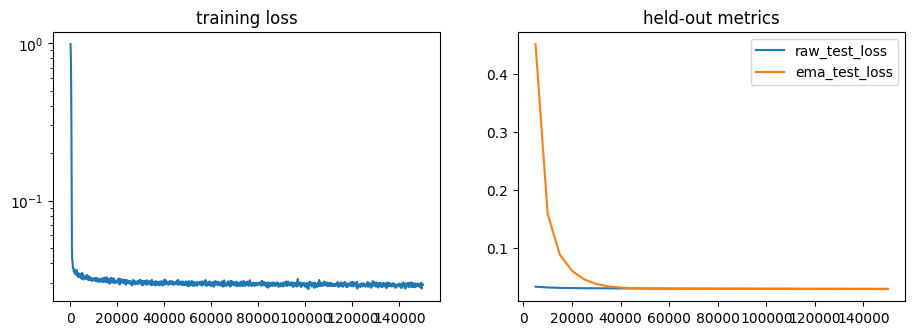

{'step': 150000, 'loss': 0.029208561405539513, 'lr': 0.0002, 'it_s': 10.657883294160097, 'gpu_h': 3.942199680894992, 'grad_norm': 0.035173822194337845, 'mem_gb': 19.42276352}


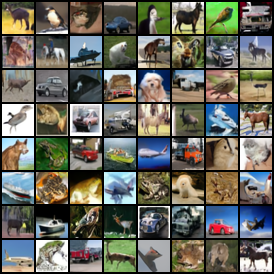

In [24]:
import json, glob
import matplotlib.pyplot as plt
from IPython.display import Image, display

RUN = 'runs/ddpm_cifar10'   # or 'runs/vae_conv_cifar10'
rows = [json.loads(l) for l in open(f'{RUN}/metrics.jsonl')]
train_rows = [r for r in rows if 'loss' in r]
eval_rows = [r for r in rows if any(k.startswith('ema_') for k in r)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([r['step'] for r in train_rows], [r['loss'] for r in train_rows]); ax[0].set_title('training loss'); ax[0].set_yscale('log')
for k in [k for k in eval_rows[-1] if k != 'step' and 'active' not in k] if eval_rows else []:
    ax[1].plot([r['step'] for r in eval_rows], [r[k] for r in eval_rows], label=k)
ax[1].legend(); ax[1].set_title('held-out metrics'); plt.show()
print(train_rows[-1])
display(Image(sorted(glob.glob(f'{RUN}/samples/*.png'))[-1]))

# Part 3 — Evaluation

**Quantitative** (10,000 samples per set, against the 50,000 training images):
FID and IS (the brief's metrics), KID, precision/recall (realism vs. diversity), likelihood in bits/dim,
FID vs. number of sampling steps (DDIM 10–250 and the paper's 1000-step sampler), sampling speed,
EMA on/off, VAE reconstruction quality, memorisation check, and a real-data reference row for every metric.

**Qualitative**: uncurated sample grids, samples grouped by class, least-recognisable samples, nearest
training images, VAE reconstructions and interpolations, the DDPM denoising process, and an optional
blind self-rating.

All results are cached in `runs/eval` on Drive; re-running a cell skips everything already done.

### `src/genmodels/eval/__init__.py`
Package marker.

In [25]:
%%writefile src/genmodels/eval/__init__.py
# Repository file: src/genmodels/eval/__init__.py

Writing src/genmodels/eval/__init__.py


### `src/genmodels/eval/metrics.py`
**Metrics.** FID, IS and KID use torch-fidelity's reference implementations on TF-compatible Inception-v3 features (extracted once per sample set). Our own code: precision/recall (realism vs. coverage, Kynkäänniemi et al. 2019), the nearest-neighbour memorisation check, PSNR/SSIM, and classifier statistics.

In [26]:
%%writefile src/genmodels/eval/metrics.py
# Repository file: src/genmodels/eval/metrics.py
"""Sample-quality metrics computed from Inception-v3 features.

FID, IS and KID use torch-fidelity's reference implementations (validated against the original
TensorFlow code used by the DDPM paper). Inception features are extracted once per sample set and
reused for every metric, including our own implementations of:
  * precision / recall (Kynkaenniemi et al., 2019): realism vs. coverage of the data,
  * nearest-neighbour memorisation check against the training set,
  * PSNR / SSIM for VAE reconstructions.
"""
import math

import numpy as np
import torch
import torch.nn.functional as F


class InceptionFeatures:
    """Pool (2048-d) features and unbiased logits of the TF-compatible Inception-v3 used for FID/IS."""

    def __init__(self, device):
        from torch_fidelity.feature_extractor_inceptionv3 import FeatureExtractorInceptionV3
        self.net = FeatureExtractorInceptionV3("inception-v3-compat", ["2048", "logits_unbiased"]).to(device).eval()
        self.device = device
        # images are resized to 299x299 inside the network: ~250 per batch needs several GB
        total_gb = torch.cuda.get_device_properties(device).total_memory / 1e9 if str(device) != "cpu" else 0
        self.batch_size = 250 if total_gb >= 12 else 32

    @torch.no_grad()
    def __call__(self, images_uint8: torch.Tensor, batch_size: int = None):
        batch_size = batch_size or self.batch_size
        pools, logits = [], []
        for i in range(0, len(images_uint8), batch_size):
            p, l = self.net(images_uint8[i:i + batch_size].to(self.device))
            pools.append(p.float().cpu())
            logits.append(l.float().cpu())
        return torch.cat(pools), torch.cat(logits)


def fid_statistics(pool: torch.Tensor):
    from torch_fidelity.metric_fid import fid_features_to_statistics
    return fid_features_to_statistics(pool.double())


def fid_from_statistics(stat_fake, stat_real) -> float:
    from torch_fidelity.metric_fid import fid_statistics_to_metric
    return float(fid_statistics_to_metric(stat_fake, stat_real, verbose=False)["frechet_inception_distance"])


def inception_score(logits: torch.Tensor, splits: int = 10):
    from torch_fidelity.metric_isc import isc_features_to_metric
    out = isc_features_to_metric(logits, splits=splits, shuffle=True, rng_seed=2020)
    return float(out["inception_score_mean"]), float(out["inception_score_std"])


def kid(pool_fake: torch.Tensor, pool_real: torch.Tensor, subset_size: int = 1000, subsets: int = 100):
    from torch_fidelity.metric_kid import kid_features_to_metric
    out = kid_features_to_metric(pool_fake, pool_real, kid_subset_size=min(subset_size, len(pool_fake)),
                                 kid_subsets=subsets, verbose=False, rng_seed=2020)
    return float(out["kernel_inception_distance_mean"]), float(out["kernel_inception_distance_std"])


def _kth_nn_radius(feats: torch.Tensor, k: int, chunk: int) -> torch.Tensor:
    """Distance from each point to its k-th nearest neighbour in the same set (self excluded)."""
    radii = []
    for i in range(0, len(feats), chunk):
        d = torch.cdist(feats[i:i + chunk], feats)
        radii.append(d.kthvalue(k + 1, dim=1).values)  # +1 skips the zero self-distance
    return torch.cat(radii)


def _covered(query: torch.Tensor, ref: torch.Tensor, ref_radii: torch.Tensor, chunk: int) -> torch.Tensor:
    """Fraction of `query` points inside at least one k-NN ball of the `ref` manifold."""
    inside = []
    for i in range(0, len(query), chunk):
        d = torch.cdist(query[i:i + chunk], ref)
        inside.append((d <= ref_radii[None]).any(dim=1))
    return torch.cat(inside).float().mean()


@torch.no_grad()
def precision_recall(pool_real, pool_fake, k: int = 3, device="cuda", chunk: int = 1000):
    """Improved precision (realism) and recall (coverage), Kynkaenniemi et al. (2019), k = 3."""
    real, fake = pool_real.to(device).float(), pool_fake.to(device).float()
    r_real, r_fake = _kth_nn_radius(real, k, chunk), _kth_nn_radius(fake, k, chunk)
    precision = _covered(fake, real, r_real, chunk).item()
    recall = _covered(real, fake, r_fake, chunk).item()
    return precision, recall


@torch.no_grad()
def nearest_neighbours(query, ref, device="cuda", chunk: int = 1000):
    """L2 nearest neighbour of every query feature among the reference features -> (dist, idx)."""
    ref = ref.to(device).float()
    dists, idxs = [], []
    for i in range(0, len(query), chunk):
        d = torch.cdist(query[i:i + chunk].to(device).float(), ref)
        v, j = d.min(dim=1)
        dists.append(v.cpu())
        idxs.append(j.cpu())
    return torch.cat(dists), torch.cat(idxs)


def memorisation_stats(nn_dist_gen: torch.Tensor, nn_dist_test: torch.Tensor):
    """Compare sample->train NN distances with real-test->train distances (the no-copying baseline).

    If a model copied training images, many samples would sit closer to the training set than almost
    any unseen real image does; `frac_below_test_p1` is ~0.01 for a model that does not copy.
    """
    p1 = torch.quantile(nn_dist_test, 0.01)
    return {"nn_dist_median": nn_dist_gen.median().item(),
            "nn_dist_median_ratio_to_test": (nn_dist_gen.median() / nn_dist_test.median()).item(),
            "frac_below_test_p1": (nn_dist_gen < p1).float().mean().item()}


def psnr(x_uint8: torch.Tensor, y_uint8: torch.Tensor) -> torch.Tensor:
    mse = ((x_uint8.float() - y_uint8.float()) ** 2).flatten(1).mean(1)
    return 10 * torch.log10(255.0 ** 2 / mse.clamp(min=1e-10))


def ssim(x_uint8: torch.Tensor, y_uint8: torch.Tensor, window: int = 11, sigma: float = 1.5) -> torch.Tensor:
    """Per-image SSIM (Wang et al., 2004) with a Gaussian window, averaged over channels."""
    x, y = x_uint8.float(), y_uint8.float()
    C = x.shape[1]
    g = torch.exp(-((torch.arange(window) - window // 2) ** 2) / (2 * sigma ** 2))
    g = (g / g.sum())
    kernel = (g[:, None] * g[None, :]).expand(C, 1, window, window).contiguous()

    def blur(t):
        return F.conv2d(t, kernel, groups=C)

    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    mx, my = blur(x), blur(y)
    vx, vy, cxy = blur(x * x) - mx ** 2, blur(y * y) - my ** 2, blur(x * y) - mx * my
    s = ((2 * mx * my + c1) * (2 * cxy + c2)) / ((mx ** 2 + my ** 2 + c1) * (vx + vy + c2))
    return s.flatten(1).mean(1)


def class_statistics(probs: torch.Tensor, num_classes: int = 10):
    """Thematic consistency from a CIFAR-10 classifier's predictions on generated images.

    confidence      mean max-probability: are samples recognisable as *some* CIFAR-10 class?
    class_entropy   normalised entropy of the predicted-class histogram: 1 = all classes equally covered
    min_class_frac  share of the rarest class (0.1 = perfectly balanced); exposes missing classes
    """
    conf, pred = probs.max(dim=1)
    hist = torch.bincount(pred, minlength=num_classes).float() / len(pred)
    nz = hist[hist > 0]
    return {"confidence": conf.mean().item(),
            "frac_confident_0.9": (conf > 0.9).float().mean().item(),
            "class_entropy": (-(nz * nz.log()).sum() / math.log(num_classes)).item(),
            "min_class_frac": hist.min().item(),
            "class_hist": hist.tolist()}

Writing src/genmodels/eval/metrics.py


### `src/genmodels/eval/classifier.py`
**CIFAR-10 classifier** (ResNet-18, trained from scratch): a measuring instrument for *thematic consistency*, i.e. how recognisable generated images are and whether every class appears.

In [27]:
%%writefile src/genmodels/eval/classifier.py
# Repository file: src/genmodels/eval/classifier.py
"""CIFAR-10 classifier (ResNet-18, CIFAR variant), trained from scratch, used only as a measuring
instrument for "thematic consistency": how recognisable generated images are, and whether every
class is represented. Typical accuracy after 30 epochs: ~94-95%.
"""
import time

import torch
import torch.nn as nn
import torch.nn.functional as F

MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]


class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(out)) + self.shortcut(x))


class ResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU())
        layers, in_ch = [], 64
        for out_ch, stride in [(64, 1), (128, 2), (256, 2), (512, 2)]:
            layers += [BasicBlock(in_ch, out_ch, stride), BasicBlock(out_ch, out_ch, 1)]
            in_ch = out_ch
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x_uint8):
        x = (x_uint8.float() / 255.0 - MEAN.to(x_uint8.device)) / STD.to(x_uint8.device)
        h = self.layers(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(h, 1).flatten(1))


def _augment(x, generator):
    """Random crop with 4-pixel zero padding + horizontal flip, per image, on the GPU."""
    N = len(x)
    xp = F.pad(x, (4, 4, 4, 4))
    dy = torch.randint(0, 9, (N,), generator=generator, device=x.device)
    dx = torch.randint(0, 9, (N,), generator=generator, device=x.device)
    rows = (dy[:, None] + torch.arange(32, device=x.device))[:, :, None]
    cols = (dx[:, None] + torch.arange(32, device=x.device))[:, None, :]
    out = xp.permute(0, 2, 3, 1)[torch.arange(N, device=x.device)[:, None, None], rows, cols].permute(0, 3, 1, 2)
    flip = torch.rand(N, generator=generator, device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], out.flip(3), out)


def train_classifier(train_x, train_y, test_x, test_y, epochs=30, batch_size=256, lr=0.1, device="cuda", log=print):
    torch.manual_seed(0)
    model = ResNet18().to(device).to(memory_format=torch.channels_last)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=5e-4)
    steps_per_epoch = len(train_x) // batch_size
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * steps_per_epoch, pct_start=0.25)
    use_bf16 = device != "cpu" and torch.cuda.get_device_capability()[0] >= 8
    train_x, train_y = train_x.to(device), train_y.to(device)
    g = torch.Generator(device).manual_seed(0)
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(train_x), generator=g, device=device)
        for i in range(steps_per_epoch):
            idx = perm[i * batch_size:(i + 1) * batch_size]
            with torch.autocast("cuda", torch.bfloat16, enabled=use_bf16):
                loss = F.cross_entropy(model(_augment(train_x[idx], g)), train_y[idx], label_smoothing=0.1)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
        acc = accuracy(model, test_x, test_y, device)
        log(f"epoch {epoch + 1}/{epochs}: loss {loss.item():.3f}, test acc {acc:.4f} ({time.time() - t0:.0f}s)")
    return model, acc


@torch.no_grad()
def predict_proba(model, x_uint8, device="cuda", batch_size=1000):
    model.eval()
    out = [F.softmax(model(x_uint8[i:i + batch_size].to(device)).float(), dim=1).cpu()
           for i in range(0, len(x_uint8), batch_size)]
    return torch.cat(out)


def accuracy(model, x, y, device="cuda"):
    return (predict_proba(model, x, device).argmax(1) == y.cpu()).float().mean().item()


def load_classifier(path, device="cuda"):
    model = ResNet18().to(device)
    model.load_state_dict(torch.load(path, map_location=device)["model"])
    return model.eval()

Writing src/genmodels/eval/classifier.py


### `src/genmodels/eval/sampling.py`
**Sampling utilities**: load a trained run and generate reproducible sample sets (fixed noise per batch).

In [28]:
%%writefile src/genmodels/eval/sampling.py
# Repository file: src/genmodels/eval/sampling.py
"""Loading trained runs and generating sample sets reproducibly.

Batch i of a sample set with seed s always uses noise seeded by (s, i), so every sample set is
reproducible, and DDIM sets with the same seed start from the same x_T (useful for comparing step counts).
"""
import time
from pathlib import Path

import numpy as np
import torch

from ..models import build_model
from ..utils import autocast_dtype, to_uint8


def load_run(run_dir, weights="ema", device="cuda", snapshot=None):
    """Model from `<run_dir>/ema_final.pt` (weights 'ema' or 'raw') or from an EMA snapshot file."""
    final = torch.load(Path(run_dir) / "ema_final.pt", map_location="cpu", weights_only=False)
    model = build_model(final["cfg"]["model"])
    if snapshot is not None:
        model.load_state_dict(torch.load(snapshot, map_location="cpu", weights_only=False)["ema"])
    else:
        model.load_state_dict(final["ema"] if weights == "ema" else final["model"])
    return model.to(device).eval(), final


def autocast(device):
    dtype = autocast_dtype("auto", torch.device(device))
    return torch.autocast("cuda", dtype=dtype or torch.float32, enabled=dtype is not None)


@torch.no_grad()
def generate(model, n, sampler="ddpm", steps=None, seed=0, batch_size=500, device="cuda"):
    """Returns (uint8 images [n, 3, 32, 32] on CPU, GPU seconds spent)."""
    out, seconds = [], 0.0
    for b, start in enumerate(range(0, n, batch_size)):
        g = torch.Generator(device).manual_seed(seed * 1_000_003 + b)
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        with autocast(device):
            x = model.sample(min(batch_size, n - start), sampler=sampler, steps=steps, generator=g, device=device)
        torch.cuda.synchronize()
        seconds += time.perf_counter() - t0
        out.append(to_uint8(x.float()).cpu())
    return torch.cat(out), seconds


@torch.no_grad()
def reconstruct(model, x_uint8, batch_size=500, device="cuda"):
    out = []
    for i in range(0, len(x_uint8), batch_size):
        with autocast(device):
            out.append(to_uint8(model.reconstruct(x_uint8[i:i + batch_size].to(device)).float()).cpu())
    return torch.cat(out)


def save_samples(path, images, **meta):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, images=images.numpy(), **meta)


def load_samples(path):
    return torch.from_numpy(np.load(path)["images"])

Writing src/genmodels/eval/sampling.py


### `scripts/train_classifier.py`
**Classifier training script.**

In [29]:
%%writefile scripts/train_classifier.py
# Repository file: scripts/train_classifier.py
"""Train the CIFAR-10 classifier used to measure thematic consistency (~10 min on an L4).

    python scripts/train_classifier.py --out runs/classifier
"""
import argparse
from pathlib import Path

import torch

from genmodels.data import load_cifar10
from genmodels.eval.classifier import train_classifier


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="runs/classifier")
    ap.add_argument("--data-root", default="data")
    ap.add_argument("--epochs", type=int, default=30)
    args = ap.parse_args()
    path = Path(args.out) / "classifier.pt"
    if path.exists():
        print(f"{path} exists (test accuracy {torch.load(path, map_location='cpu')['test_accuracy']:.4f}); skipping")
        return
    train_x, train_y = load_cifar10(args.data_root, train=True)
    test_x, test_y = load_cifar10(args.data_root, train=False)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, acc = train_classifier(train_x, train_y, test_x, test_y, epochs=args.epochs, device=device)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"model": model.state_dict(), "test_accuracy": acc, "epochs": args.epochs}, path)
    print(f"saved {path}: test accuracy {acc:.4f}")


if __name__ == "__main__":
    main()

Writing scripts/train_classifier.py


### `scripts/evaluate.py`
**The evaluation protocol** (resumable: finished items are cached on Drive): reference statistics, every sample set, FID during training, bits/dim, and sampling speed.

In [30]:
%%writefile scripts/evaluate.py
# Repository file: scripts/evaluate.py
"""Full evaluation protocol. Resumable: every finished item is cached under --eval-dir and skipped
when the script is re-run, so a Colab disconnect only loses the item in progress.

Stages
  reference  Inception features / FID statistics of CIFAR-10 train (50k) and test (10k); real-data
             reference row (the ceiling every metric can reach).
  samples    sample sets of every model: FID, IS, KID, precision/recall, classifier-based thematic
             consistency, memorisation check; reconstructions (VAE) with PSNR / SSIM / FID.
  curves     FID during training from the EMA snapshots (5k samples; DDPM with 50 DDIM steps).
  bpd        likelihood bound in bits/dim on the test set (DDPM: full variational bound, VAE: ELBO).
  timing     sampling throughput (batch 256) and single-image latency on this GPU.

    python scripts/evaluate.py                      # everything, 10k samples per set
    python scripts/evaluate.py --stages samples     # one stage
    python scripts/evaluate.py --quick              # small smoke-test version
"""
import argparse
import json
import math
import time
from pathlib import Path

import numpy as np
import torch

from genmodels.data import load_cifar10
from genmodels.eval import metrics as M
from genmodels.eval.classifier import load_classifier, predict_proba
from genmodels.eval.sampling import autocast, generate, load_run, load_samples, reconstruct, save_samples

DDIM_STEPS = [10, 25, 50, 100, 250]


def sample_set_specs(args):
    """Every sample set of the protocol. `family` is the run; `kind` is 'sample' or 'recon'."""
    n = args.n
    specs = []
    if args.mlp:
        specs += [dict(key=f"vae_mlp_s{s}", family="mlp", label="VAE (paper MLP)", seed=s, n=n) for s in range(3)]
        specs += [dict(key="vae_mlp_recon", family="mlp", label="VAE (paper MLP) reconstructions", kind="recon")]
    if args.vae:
        specs += [dict(key=f"vae_conv_s{s}", family="vae", label="VAE (conv)", seed=s, n=n) for s in range(3)]
        specs += [dict(key="vae_conv_raw_s0", family="vae", label="VAE (conv), no EMA", weights="raw", seed=0, n=n),
                  dict(key="vae_conv_recon", family="vae", label="VAE (conv) reconstructions", kind="recon")]
    if args.ddpm:
        specs += [dict(key="ddpm_ancestral1000_s0", family="ddpm", label="DDPM (1000 ancestral steps)",
                       sampler="ddpm", steps=1000, seed=0, n=n)]
        specs += [dict(key=f"ddpm_ddim{k}_s0", family="ddpm", label=f"DDPM (DDIM {k} steps)", sampler="ddim",
                       steps=k, seed=0, n=n) for k in DDIM_STEPS]
        specs += [dict(key=f"ddpm_ddim100_s{s}", family="ddpm", label="DDPM (DDIM 100 steps)", sampler="ddim",
                       steps=100, seed=s, n=n) for s in (1, 2)]
        specs += [dict(key="ddpm_raw_ddim100_s0", family="ddpm", label="DDPM (DDIM 100 steps), no EMA",
                       weights="raw", sampler="ddim", steps=100, seed=0, n=n)]
    for s in specs:
        s.setdefault("kind", "sample")
        s.setdefault("weights", "ema")
        s.setdefault("sampler", None)
        s.setdefault("steps", None)
        s["nfe"] = 1 if s["family"] in ("vae", "mlp") else s["steps"]
    if args.quick:
        for s in specs:
            if s["kind"] == "sample":
                s["n"] = min(s["n"], 200 if s["family"] == "ddpm" else 1000)
    return specs


class Evaluator:
    def __init__(self, args):
        self.args = args
        self.dev = "cuda"
        self.out = Path(args.eval_dir)
        for sub in ("samples", "items", "curves"):
            (self.out / sub).mkdir(parents=True, exist_ok=True)
        self.train_x, self.train_y = load_cifar10(args.data_root, train=True)
        self.test_x, self.test_y = load_cifar10(args.data_root, train=False)
        if args.quick:
            self.test_x, self.test_y = self.test_x[:1000], self.test_y[:1000]
        self._inception, self._classifier, self._models, self._ref = None, None, {}, None
        self.runs = {"ddpm": args.ddpm, "vae": args.vae, "mlp": args.mlp}

    # ---- lazily created tools ---------------------------------------------------------------
    @property
    def inception(self):
        if self._inception is None:
            self._inception = M.InceptionFeatures(self.dev)
        return self._inception

    @property
    def classifier(self):
        if self._classifier is None and Path(self.args.classifier).exists():
            self._classifier = load_classifier(self.args.classifier, self.dev)
        return self._classifier

    def model(self, family, weights="ema"):
        key = (family, weights)
        if key not in self._models:
            self._models = {}  # keep one model in memory at a time
            torch.cuda.empty_cache()
            self._models[key] = load_run(self.runs[family], weights, self.dev)
        return self._models[key][0]

    # ---- reference statistics -----------------------------------------------------------------
    def reference(self):
        path = self.out / "reference.pt"
        if self._ref is None and path.exists():
            self._ref = torch.load(path, weights_only=False)
        if self._ref is not None:
            return self._ref
        print("computing Inception features of CIFAR-10 train (50k) and test ...")
        train_pool, _ = self.inception(self.train_x)
        test_pool, test_logits = self.inception(self.test_x)
        g = torch.Generator().manual_seed(0)
        pr_idx = torch.randperm(len(train_pool), generator=g)[:len(self.test_x)]
        test_nn, _ = M.nearest_neighbours(test_pool, train_pool, self.dev)
        self._ref = {"train_stats": M.fid_statistics(train_pool), "train_pool": train_pool.half(),
                     "pr_idx": pr_idx, "test_pool": test_pool.half(), "test_logits": test_logits,
                     "test_nn_dist": test_nn}
        torch.save(self._ref, path)
        return self._ref

    # ---- one sample set -------------------------------------------------------------------------
    def evaluate_images(self, images, spec, compare_to=None):
        """All metrics of one set of uint8 images; `compare_to` = paired originals for reconstructions."""
        ref = self.reference()
        train_pool = ref["train_pool"].float()
        pool, logits = self.inception(images)
        res = {"n": len(images),
               "fid": M.fid_from_statistics(M.fid_statistics(pool), ref["train_stats"])}
        res["is_mean"], res["is_std"] = M.inception_score(logits)
        res["kid_mean"], res["kid_std"] = M.kid(pool, train_pool)
        res["precision"], res["recall"] = M.precision_recall(train_pool[ref["pr_idx"][:len(pool)]], pool, device=self.dev)
        nn_dist, nn_idx = M.nearest_neighbours(pool, train_pool, self.dev)
        res.update(M.memorisation_stats(nn_dist, ref["test_nn_dist"]))
        per_sample = {"nn_dist": nn_dist.numpy(), "nn_idx": nn_idx.numpy()}
        if self.classifier is not None:
            probs = predict_proba(self.classifier, images, self.dev)
            res.update(M.class_statistics(probs))
            per_sample["confidence"], per_sample["pred"] = (t.numpy() for t in probs.max(1))
        if compare_to is not None:
            res["psnr"] = M.psnr(images, compare_to).mean().item()
            res["ssim"] = M.ssim(images, compare_to).mean().item()
        return res, per_sample

    def run_spec(self, spec):
        item_path = self.out / "items" / f"{spec['key']}.json"
        if item_path.exists():
            return
        print(f"[{spec['key']}] {spec['label']}")
        sample_path = self.out / "samples" / f"{spec['key']}.npz"
        compare_to, seconds = None, None
        if sample_path.exists():
            images = load_samples(sample_path)
            seconds = float(np.load(sample_path).get("seconds", np.nan))
        elif spec["kind"] == "recon":
            images = reconstruct(self.model(spec["family"]), self.test_x, device=self.dev)
            save_samples(sample_path, images)
        else:
            images, seconds = generate(self.model(spec["family"], spec["weights"]), spec["n"], spec["sampler"],
                                       spec["steps"], spec["seed"], self.args.batch_size, self.dev)
            save_samples(sample_path, images, seconds=seconds)
        if spec["kind"] == "recon":
            compare_to = self.test_x
        res, per_sample = self.evaluate_images(images, spec, compare_to)
        res.update({k: v for k, v in spec.items() if k != "n"}, sample_gpu_seconds=seconds)
        np.savez(self.out / "items" / f"{spec['key']}_per_sample.npz", **per_sample)
        item_path.write_text(json.dumps(res, indent=1))
        print("   " + ", ".join(f"{k}={res[k]:.4g}" for k in ("fid", "is_mean", "precision", "recall") if k in res))

    def real_reference(self):
        spec = dict(key="real_test", family="real", label="Real CIFAR-10 test images", kind="real", nfe=0)
        item_path = self.out / "items" / "real_test.json"
        if item_path.exists():
            return
        res, per_sample = self.evaluate_images(self.test_x, spec)
        if self.classifier is not None:
            res["classifier_accuracy"] = float((per_sample["pred"] == self.test_y.numpy()).mean())
        res.update(spec)
        np.savez(self.out / "items" / "real_test_per_sample.npz", **per_sample)
        item_path.write_text(json.dumps(res, indent=1))
        print(f"[real_test] FID {res['fid']:.2f}, IS {res['is_mean']:.2f}")

    # ---- FID during training --------------------------------------------------------------------
    def curves(self):
        n = 1000 if self.args.quick else self.args.curve_n
        ref = self.reference()
        for family in ("ddpm", "vae"):
            run = self.runs[family]
            if not run:
                continue
            for snap in sorted(Path(run, "snapshots").glob("ema_*.pt")):
                step = int(snap.stem.split("_")[1])
                path = self.out / "curves" / f"{family}_{step:07d}.json"
                if path.exists():
                    continue
                model, _ = load_run(run, device=self.dev, snapshot=snap)
                images, _ = generate(model, n, "ddim", 50, seed=0, batch_size=self.args.batch_size, device=self.dev)
                pool, logits = self.inception(images)
                res = {"family": family, "step": step, "n": n, "sampler": "ddim50" if family == "ddpm" else "prior",
                       "fid": M.fid_from_statistics(M.fid_statistics(pool), ref["train_stats"]),
                       "is_mean": M.inception_score(logits)[0]}
                path.write_text(json.dumps(res))
                print(f"[curve] {family} step {step}: FID-{n // 1000}k {res['fid']:.2f}")
                del model
                torch.cuda.empty_cache()

    # ---- likelihood ---------------------------------------------------------------------------------
    @torch.no_grad()
    def bpd(self):
        path = self.out / "bpd.json"
        out = json.loads(path.read_text()) if path.exists() else {}
        g = torch.Generator(self.dev)
        for family in ("vae", "mlp"):
            if self.runs[family] and family not in out:
                model = self.model(family)
                vals, recon, kl = [], [], []
                g.manual_seed(0)
                for i in range(0, len(self.test_x), 500):
                    x = model.dequantize(self.test_x[i:i + 500].to(self.dev), g)
                    r = model.neg_elbo(x, g)
                    vals.append(model.nats_to_bpd(r["neg_elbo"], x[0].numel()).cpu())
                    recon.append(r["recon"].cpu())
                    kl.append(r["kl"].cpu())
                vals = torch.cat(vals)
                out[family] = {"bpd": vals.mean().item(), "bpd_sem": (vals.std() / math.sqrt(len(vals))).item(),
                               "recon_nats": torch.cat(recon).mean().item(), "kl_nats": torch.cat(kl).mean().item(),
                               "n": len(vals)}
                path.write_text(json.dumps(out, indent=1))
                print(f"[bpd] {family}: {out[family]['bpd']:.3f} bits/dim")
        if self.runs["ddpm"] and "ddpm" not in out:
            model = self.model("ddpm")
            n = 8 if self.args.quick else self.args.bpd_images
            totals = {"fixedlarge": [], "fixedsmall": []}
            terms = {"fixedlarge": 0.0, "fixedsmall": 0.0}
            g.manual_seed(0)
            for i in range(0, n, 250):
                x0 = model.preprocess(self.test_x[i:min(n, i + 250)].to(self.dev))
                t0 = time.time()
                # full fp32: the likelihood bound is a precise quantity, so no bf16 here
                res = model.diffusion.calc_bpd(model.net, x0, ("fixedlarge", "fixedsmall"), generator=g)
                for v in totals:
                    totals[v].append(res[v]["total"].cpu())
                    terms[v] = terms[v] + res[v]["terms"].sum(0).cpu()
                print(f"   bpd batch {i // 250 + 1}: {time.time() - t0:.0f}s")
            out["ddpm"] = {}
            for v in totals:
                vals = torch.cat(totals[v])
                out["ddpm"][v] = {"bpd": vals.mean().item(), "bpd_sem": (vals.std() / math.sqrt(len(vals))).item(),
                                  "terms_mean": (terms[v] / len(vals)).tolist(), "n": len(vals)}
            path.write_text(json.dumps(out, indent=1))
            print(f"[bpd] ddpm: {out['ddpm']['fixedlarge']['bpd']:.3f} (sigma^2=beta), "
                  f"{out['ddpm']['fixedsmall']['bpd']:.3f} (sigma^2=beta~) bits/dim")

    # ---- speed ----------------------------------------------------------------------------------------
    @torch.no_grad()
    def timing(self):
        path = self.out / "timing.json"
        out = json.loads(path.read_text()) if path.exists() else {}
        out["gpu"] = torch.cuda.get_device_name()
        configs = [("mlp", None, None), ("vae", None, None), ("ddpm", "ddpm", 1000)] + \
                  [("ddpm", "ddim", k) for k in DDIM_STEPS]
        for family, sampler, steps in configs:
            key = f"{family}_{sampler or 'prior'}{steps or ''}"
            if not self.runs[family] or key in out:
                continue
            model = self.model(family)
            row = {"family": family, "sampler": sampler, "steps": steps, "nfe": steps or 1}
            for batch, name in [(256, "throughput_img_s"), (1, "latency_s")]:
                generate(model, batch, "ddim" if sampler else None, 5 if sampler else None, seed=1,
                         batch_size=batch, device=self.dev)  # warm-up / autotune
                _, sec = generate(model, batch, sampler, steps, seed=0, batch_size=batch, device=self.dev)
                row[name] = batch / sec if batch > 1 else sec
            out[key] = row
            path.write_text(json.dumps(out, indent=1))
            print(f"[timing] {key}: {row['throughput_img_s']:.1f} img/s (batch 256), {row['latency_s'] * 1000:.1f} ms/img (batch 1)")

    def run_info(self):
        info = {}
        for family, run in self.runs.items():
            if run and Path(run, "ema_final.pt").exists():
                f = torch.load(Path(run) / "ema_final.pt", map_location="cpu", weights_only=False)
                info[family] = {"run": str(run), "steps": f["step"], "train_gpu_hours": f["train_seconds"] / 3600,
                                "gpus": f["gpus"], "n_params": f["n_params"], "config": f["cfg"]}
        (self.out / "runs.json").write_text(json.dumps(info, indent=1))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--eval-dir", default="runs/eval")
    ap.add_argument("--data-root", default="data")
    ap.add_argument("--ddpm", default="runs/ddpm_cifar10")
    ap.add_argument("--vae", default="runs/vae_conv_cifar10")
    ap.add_argument("--mlp", default="runs/vae_mlp_cifar10")
    ap.add_argument("--classifier", default="runs/classifier/classifier.pt")
    ap.add_argument("--stages", nargs="*", default=["reference", "samples", "curves", "bpd", "timing"])
    ap.add_argument("--n", type=int, default=10000, help="samples per set")
    ap.add_argument("--curve-n", type=int, default=5000)
    ap.add_argument("--bpd-images", type=int, default=1000)
    ap.add_argument("--batch-size", type=int, default=500)
    ap.add_argument("--quick", action="store_true", help="small sets for a smoke test")
    args = ap.parse_args()
    if args.quick and args.eval_dir == "runs/eval":
        args.eval_dir = "runs/eval_quick"  # smoke-test results never mix with the real ones
    for name in ("ddpm", "vae", "mlp"):  # runs that do not exist (yet) are skipped
        if not Path(getattr(args, name), "ema_final.pt").exists():
            print(f"note: no finished run at {getattr(args, name)}; skipping {name}")
            setattr(args, name, None)
    torch.backends.cudnn.benchmark = True

    ev = Evaluator(args)
    ev.run_info()
    if "reference" in args.stages:
        ev.reference()
        ev.real_reference()
    if "samples" in args.stages:
        for spec in sample_set_specs(args):
            ev.run_spec(spec)
    if "curves" in args.stages:
        ev.curves()
    if "bpd" in args.stages:
        ev.bpd()
    if "timing" in args.stages:
        ev.timing()
    print(f"done; results in {ev.out}")


if __name__ == "__main__":
    main()

Writing scripts/evaluate.py


### `scripts/make_figures.py`
**Result tables and figures** from the cached evaluation.

In [31]:
%%writefile scripts/make_figures.py
# Repository file: scripts/make_figures.py
"""Turn the cached evaluation results into result tables (results.md, results.csv) and figures.

    python scripts/make_figures.py --eval-dir runs/eval --out runs/eval/report
    python scripts/make_figures.py ... --model-figures   # also figures that need the trained models
"""
import argparse
import csv
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch

from genmodels.data import load_cifar10
from genmodels.eval.classifier import CLASSES
from genmodels.eval.sampling import autocast, load_run, load_samples
from genmodels.utils import to_uint8

MODELS = [  # (display name, sample-set key prefix, colour)
    ("VAE (paper MLP)", "vae_mlp", "#9e9e9e"),
    ("VAE (conv)", "vae_conv", "#1f77b4"),
    ("DDPM", "ddpm_ancestral1000", "#d62728"),
]


def grid(images, nrow, pad=1):
    """uint8 [N, 3, H, W] -> HWC array tiled nrow per row, white padding."""
    images = np.asarray(images)
    n, c, h, w = images.shape
    rows = int(np.ceil(n / nrow))
    out = np.full((rows * (h + pad) + pad, nrow * (w + pad) + pad, c), 255, np.uint8)
    for i, im in enumerate(images):
        r, k = divmod(i, nrow)
        out[pad + r * (h + pad):pad + r * (h + pad) + h, pad + k * (w + pad):pad + k * (w + pad) + w] = im.transpose(1, 2, 0)
    return out


def show(ax, img, title=None):
    ax.imshow(img, interpolation="nearest")
    ax.set_xticks([]), ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


class Report:
    def __init__(self, eval_dir, out_dir, data_root):
        self.ed, self.out = Path(eval_dir), Path(out_dir)
        self.out.mkdir(parents=True, exist_ok=True)
        self.items = {p.stem: json.loads(p.read_text()) for p in (self.ed / "items").glob("*.json")}
        self.bpd = json.loads((self.ed / "bpd.json").read_text()) if (self.ed / "bpd.json").exists() else {}
        self.timing = json.loads((self.ed / "timing.json").read_text()) if (self.ed / "timing.json").exists() else {}
        self.runs = json.loads((self.ed / "runs.json").read_text()) if (self.ed / "runs.json").exists() else {}
        self.curves = [json.loads(p.read_text()) for p in sorted((self.ed / "curves").glob("*.json"))]
        self.data_root = data_root
        self._train = None

    @property
    def train_x(self):
        if self._train is None:
            self._train = load_cifar10(self.data_root, train=True)[0]
        return self._train

    def samples(self, key):
        p = self.ed / "samples" / f"{key}.npz"
        return load_samples(p).numpy() if p.exists() else None

    def per_sample(self, key):
        p = self.ed / "items" / f"{key}_per_sample.npz"
        return np.load(p) if p.exists() else None

    def save(self, fig, name):
        fig.savefig(self.out / name, dpi=150, bbox_inches="tight")
        plt.close(fig)
        print("wrote", self.out / name)

    # ---- aggregation over seeds -----------------------------------------------------------------
    def agg(self, prefix, metric):
        vals = [v[metric] for k, v in self.items.items() if (k == prefix or k.startswith(prefix + "_s")) and metric in v]
        if not vals:
            return None, None
        return float(np.mean(vals)), (float(np.std(vals, ddof=1)) if len(vals) > 1 else None)

    def fmt(self, prefix, metric, digits=2, scale=1.0):
        m, s = self.agg(prefix, metric)
        if m is None:
            return "–"
        return f"{m * scale:.{digits}f}" + (f" ± {s * scale:.{digits}f}" if s is not None else "")

    # ---- tables -----------------------------------------------------------------------------------
    def tables(self):
        L = ["# Results\n", "All sample-based metrics use 10,000 samples against the 50,000 CIFAR-10 training images "
             "(FID-10k: systematically a little higher than the FID-50k reported in papers). "
             "± is the standard deviation over 3 independent sample sets (evaluation noise, not training-seed variance).\n"]
        fam = {"vae_mlp": "mlp", "vae_conv": "vae", "ddpm_ancestral1000": "ddpm", "ddpm_ddim100": "ddpm"}
        tkey = {"vae_mlp": "mlp_prior", "vae_conv": "vae_prior", "ddpm_ancestral1000": "ddpm_ddpm1000",
                "ddpm_ddim100": "ddpm_ddim100"}
        L += ["## Main comparison\n",
              "| Model | FID ↓ | IS ↑ | KID ×10³ ↓ | Precision ↑ | Recall ↑ | NLL bound (bits/dim) ↓ | NFE / image | Images/s ↑ | Params | Train GPU-h |",
              "|---|---|---|---|---|---|---|---|---|---|---|"]
        real = self.items.get("real_test")
        if real:
            L.append(f"| *Real test images (reference)* | {real['fid']:.2f} | {real['is_mean']:.2f} | "
                     f"{real['kid_mean'] * 1e3:.2f} | {real['precision']:.3f} | {real['recall']:.3f} | – | – | – | – | – |")
        rows = [("VAE — paper MLP", "vae_mlp"), ("VAE — conv", "vae_conv"),
                ("DDPM — 1000 ancestral steps (paper sampler)", "ddpm_ancestral1000"), ("DDPM — 100 DDIM steps", "ddpm_ddim100")]
        for name, prefix in rows:
            if self.agg(prefix, "fid")[0] is None:
                continue
            f = fam[prefix]
            b = self.bpd.get(f, {})
            b = b.get("fixedlarge", b)
            bpd = f"{b['bpd']:.3f}" if "bpd" in b else "–"
            t = self.timing.get(tkey[prefix], {})
            r = self.runs.get(f, {})
            nfe = {"vae_mlp": 1, "vae_conv": 1, "ddpm_ancestral1000": 1000, "ddpm_ddim100": 100}[prefix]
            L.append(f"| {name} | {self.fmt(prefix, 'fid')} | {self.fmt(prefix, 'is_mean')} | {self.fmt(prefix, 'kid_mean', 2, 1e3)} | "
                     f"{self.fmt(prefix, 'precision', 3)} | {self.fmt(prefix, 'recall', 3)} | {bpd} | {nfe} | "
                     f"{t.get('throughput_img_s', float('nan')):,.1f} | {r.get('n_params', 0) / 1e6:.1f}M | "
                     f"{r.get('train_gpu_hours', float('nan')):.2f} |")
        if self.timing.get("gpu"):
            L.append(f"\nSpeed measured on {self.timing['gpu']} (batch 256, bf16). Paper reference (DDPM, FID-50k): "
                     "FID 3.17, IS 9.46, NLL ≤ 3.75 bits/dim after 800k steps.\n")

        L += ["## DDPM: sampling steps vs. quality (same network, same starting noise)\n",
              "| Sampler | NFE | FID ↓ | IS ↑ | Precision | Recall | Images/s (batch 256) | Latency, 1 image |",
              "|---|---|---|---|---|---|---|---|"]
        for key, tk, name in [("ddpm_ancestral1000_s0", "ddpm_ddpm1000", "Ancestral (paper)")] + \
                [(f"ddpm_ddim{k}_s0", f"ddpm_ddim{k}", "DDIM") for k in (10, 25, 50, 100, 250)]:
            if key in self.items:
                v, t = self.items[key], self.timing.get(tk, {})
                L.append(f"| {name} | {v['nfe']} | {v['fid']:.2f} | {v['is_mean']:.2f} | {v['precision']:.3f} | "
                         f"{v['recall']:.3f} | {t.get('throughput_img_s', float('nan')):,.1f} | {t.get('latency_s', float('nan')):.2f} s |")
        for k, name in [("vae_prior", "VAE (conv)"), ("mlp_prior", "VAE (MLP)")]:
            t = self.timing.get(k)
            if t:
                L.append(f"| {name}, for comparison | 1 | | | | | {t['throughput_img_s']:,.1f} | {t['latency_s'] * 1000:.1f} ms |")

        L += ["\n## Ablations that need no extra training\n", "| Comparison | FID ↓ | IS ↑ | Precision | Recall |", "|---|---|---|---|---|"]
        for key, name in [("ddpm_ddim100_s0", "DDPM, DDIM-100, EMA weights"), ("ddpm_raw_ddim100_s0", "DDPM, DDIM-100, raw weights"),
                          ("vae_conv_s0", "VAE (conv), EMA weights"), ("vae_conv_raw_s0", "VAE (conv), raw weights"),
                          ("vae_conv_recon", "VAE (conv) reconstructions of test images"), ("vae_mlp_recon", "VAE (MLP) reconstructions")]:
            if key in self.items:
                v = self.items[key]
                L.append(f"| {name} | {v['fid']:.2f} | {v['is_mean']:.2f} | {v['precision']:.3f} | {v['recall']:.3f} |")
        for key, name in [("vae_conv_recon", "VAE (conv)"), ("vae_mlp_recon", "VAE (MLP)")]:
            if key in self.items:
                v = self.items[key]
                L.append(f"\n{name} reconstruction quality on the test set: PSNR {v['psnr']:.2f} dB, SSIM {v['ssim']:.3f}.")

        L += ["\n## Thematic consistency (CIFAR-10 classifier on generated images)\n",
              "| Images | Mean confidence ↑ | Share with confidence > 0.9 ↑ | Class-histogram entropy (1 = all classes equal) | Rarest class share (0.10 = balanced) |",
              "|---|---|---|---|---|"]
        for key, name in [("real_test", "Real test images"), ("vae_mlp_s0", "VAE (MLP)"), ("vae_conv_s0", "VAE (conv)"),
                          ("ddpm_ancestral1000_s0", "DDPM (1000 steps)"), ("ddpm_ddim100_s0", "DDPM (DDIM 100)")]:
            v = self.items.get(key, {})
            if "confidence" in v:
                L.append(f"| {name} | {v['confidence']:.3f} | {v['frac_confident_0.9']:.3f} | {v['class_entropy']:.3f} | {v['min_class_frac']:.3f} |")
        if real and "classifier_accuracy" in real:
            L.append(f"\nClassifier accuracy on the real test set: {real['classifier_accuracy']:.4f}.")

        L += ["\n## Memorisation check\n",
              "Distance from each sample to its nearest training image (Inception features), relative to the same distance "
              "for unseen real test images. A copying model would have many samples closer than 99% of real test images "
              "(last column ≫ 0.01).\n",
              "| Model | Median NN distance / real-test median | Share closer than the real-test 1st percentile |", "|---|---|---|"]
        for key, name in [("vae_mlp_s0", "VAE (MLP)"), ("vae_conv_s0", "VAE (conv)"), ("ddpm_ancestral1000_s0", "DDPM")]:
            if key in self.items:
                v = self.items[key]
                L.append(f"| {name} | {v['nn_dist_median_ratio_to_test']:.3f} | {v['frac_below_test_p1']:.4f} |")

        if self.bpd:
            L += ["\n## Likelihood (upper bounds on the test-set NLL, bits/dim)\n", "| Model | bits/dim ↓ |", "|---|---|"]
            for f, name in [("mlp", "VAE (MLP), ELBO"), ("vae", "VAE (conv), ELBO")]:
                if f in self.bpd:
                    L.append(f"| {name} | {self.bpd[f]['bpd']:.3f} ± {self.bpd[f]['bpd_sem']:.3f} |")
            if "ddpm" in self.bpd:
                for v, name in [("fixedlarge", "σ²=β"), ("fixedsmall", "σ²=β̃")]:
                    d = self.bpd["ddpm"][v]
                    L.append(f"| DDPM, variational bound, {name} ({d['n']} test images) | {d['bpd']:.3f} ± {d['bpd_sem']:.3f} |")

        blind = self.ed / "blind" / "score.json"
        if blind.exists():
            s = json.loads(blind.read_text())
            L += ["\n## Blind human rating (single rater)\n", "| Source | Mean realism (1–5) | Recognised correctly | Judged 'real' |",
                  "|---|---|---|---|"]
            for src, v in s["by_source"].items():
                L.append(f"| {src} | {v['realism']:.2f} | {v['recognised']:.2f} | {v['judged_real']:.2f} |")

        (self.out / "results.md").write_text("\n".join(L) + "\n", encoding="utf-8")
        with open(self.out / "results.csv", "w", newline="") as f:
            keys = sorted({k for v in self.items.values() for k, x in v.items() if not isinstance(x, (list, dict))})
            w = csv.DictWriter(f, ["key"] + keys)
            w.writeheader()
            for k, v in sorted(self.items.items()):
                w.writerow({"key": k, **{a: b for a, b in v.items() if a in keys}})
        print("wrote", self.out / "results.md")

    # ---- figures from cached samples ---------------------------------------------------------------
    def fig_samples(self):
        panels = [("Real CIFAR-10", None)] + [(n, k) for n, k, _ in MODELS]
        panels = [(n, k) for n, k in panels if k is None or self.samples(f"{k}_s0") is not None]
        fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.6))
        for ax, (name, key) in zip(np.atleast_1d(axes), panels):
            imgs = load_cifar10(self.data_root, train=False)[0][:100].numpy() if key is None else self.samples(f"{key}_s0")[:100]
            show(ax, grid(imgs, 10), name)
        fig.suptitle("Uncurated samples (first 100, fixed seed)")
        self.save(fig, "fig_samples.png")

    def fig_speed_quality(self):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
        pts = [(self.items[k]["nfe"], self.items[k]["fid"], k) for k in self.items if k.startswith("ddpm_ddim") and k.endswith("_s0")]
        pts.sort()
        if pts:
            axes[0].plot([p[0] for p in pts], [p[1] for p in pts], "o-", color="#d62728", label="DDPM, DDIM")
        if "ddpm_ancestral1000_s0" in self.items:
            axes[0].plot(1000, self.items["ddpm_ancestral1000_s0"]["fid"], "*", ms=14, color="#d62728", label="DDPM, ancestral (paper)")
        for name, key, c in MODELS[:2]:
            if f"{key}_s0" in self.items:
                axes[0].plot(1, self.items[f"{key}_s0"]["fid"], "s", ms=9, color=c, label=name)
        if "real_test" in self.items:
            axes[0].axhline(self.items["real_test"]["fid"], ls="--", c="k", lw=1, label="real test images")
        axes[0].set(xscale="log", yscale="log", xlabel="network evaluations per image (NFE)", ylabel="FID-10k ↓",
                    title="Quality vs. sampling cost")
        axes[0].legend(fontsize=8)
        tk = [(f"ddpm_ddim{k}_s0", f"ddpm_ddim{k}") for k in (10, 25, 50, 100, 250)] + [("ddpm_ancestral1000_s0", "ddpm_ddpm1000")]
        xs = [(self.timing[t]["throughput_img_s"], self.items[k]["fid"]) for k, t in tk if k in self.items and t in self.timing]
        if xs:
            axes[1].plot(*zip(*sorted(xs)), "o-", color="#d62728", label="DDPM")
        for (name, key, c), t in zip(MODELS[:2], ("mlp_prior", "vae_prior")):
            if f"{key}_s0" in self.items and t in self.timing:
                axes[1].plot(self.timing[t]["throughput_img_s"], self.items[f"{key}_s0"]["fid"], "s", ms=9, color=c, label=name)
        axes[1].set(xscale="log", yscale="log", xlabel=f"images per second ({self.timing.get('gpu', 'GPU')}, batch 256)",
                    ylabel="FID-10k ↓", title="Quality vs. measured speed")
        axes[1].legend(fontsize=8)
        self.save(fig, "fig_speed_quality.png")

    def fig_precision_recall(self):
        fig, ax = plt.subplots(figsize=(5.5, 5))
        for key, name, c, m in [("real_test", "real test", "k", "*"), ("vae_mlp_s0", "VAE (MLP)", "#9e9e9e", "s"),
                                ("vae_conv_s0", "VAE (conv)", "#1f77b4", "s"), ("ddpm_ancestral1000_s0", "DDPM (1000)", "#d62728", "o"),
                                ("ddpm_ddim10_s0", "DDPM (DDIM 10)", "#ff9896", "o"), ("vae_conv_recon", "VAE recon.", "#aec7e8", "^")]:
            if key in self.items:
                v = self.items[key]
                ax.scatter(v["recall"], v["precision"], c=c, marker=m, s=90, label=name)
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="recall (diversity / coverage) →", ylabel="precision (realism) →",
               title="Quality vs. diversity")
        ax.legend(fontsize=8, loc="lower left")
        self.save(fig, "fig_precision_recall.png")

    def fig_training_curves(self):
        if not self.curves:
            return
        fig, ax = plt.subplots(figsize=(6.5, 4))
        for fam, name, c in [("ddpm", "DDPM (DDIM-50)", "#d62728"), ("vae", "VAE (conv)", "#1f77b4")]:
            pts = sorted((r["step"], r["fid"]) for r in self.curves if r["family"] == fam)
            if pts:
                ax.plot(*zip(*pts), "o-", c=c, label=name)
        ax.set(yscale="log", xlabel="training step", ylabel=f"FID-{self.curves[0]['n'] // 1000}k (EMA weights) ↓",
               title="Sample quality during training")
        ax.legend()
        self.save(fig, "fig_fid_during_training.png")

    def fig_classes(self):
        rows = [(k, n, c) for k, n, c in [("real_test", "real test", "k"), ("vae_mlp_s0", "VAE (MLP)", "#9e9e9e"),
                                          ("vae_conv_s0", "VAE (conv)", "#1f77b4"), ("ddpm_ancestral1000_s0", "DDPM", "#d62728")]
                if "class_hist" in self.items.get(k, {})]
        if not rows:
            return
        fig, ax = plt.subplots(figsize=(11, 3.8))
        w = 0.8 / len(rows)
        for i, (k, n, c) in enumerate(rows):
            ax.bar(np.arange(10) + i * w, self.items[k]["class_hist"], w, color=c, label=n)
        ax.axhline(0.1, ls="--", c="k", lw=1)
        ax.set_xticks(np.arange(10) + 0.4 - w / 2, CLASSES)
        ax.set(ylabel="share of images", title="Predicted-class distribution (thematic coverage)")
        ax.legend(fontsize=8)
        self.save(fig, "fig_class_distribution.png")

    def fig_by_class(self):
        for key, name in [("ddpm_ancestral1000_s0", "DDPM"), ("vae_conv_s0", "VAE (conv)")]:
            ps, imgs = self.per_sample(key), self.samples(key)
            if ps is None or imgs is None or "pred" not in ps:
                continue
            rows = []
            for c in range(10):
                idx = np.where(ps["pred"] == c)[0]
                idx = idx[np.argsort(-ps["confidence"][idx])][:10]
                block = np.full((10, 3, 32, 32), 255, np.uint8)
                block[:len(idx)] = imgs[idx]
                rows.append(block)
            fig, ax = plt.subplots(figsize=(5.5, 6))
            show(ax, grid(np.concatenate(rows), 10), f"{name}: most confident samples per predicted class")
            ax.set_yticks(np.arange(10) * 33 + 17, CLASSES, fontsize=8)
            self.save(fig, f"fig_by_class_{key.split('_')[0]}_{key.split('_')[1]}.png")

    def fig_failures(self):
        panels = []
        for key, name in [("vae_conv_s0", "VAE (conv)"), ("ddpm_ancestral1000_s0", "DDPM")]:
            ps, imgs = self.per_sample(key), self.samples(key)
            if ps is not None and imgs is not None and "confidence" in ps:
                panels.append((name, imgs[np.argsort(ps["confidence"])[:32]]))
        if not panels:
            return
        fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 3.4))
        for ax, (name, imgs) in zip(np.atleast_1d(axes), panels):
            show(ax, grid(imgs, 8), f"{name}: 32 least recognisable samples")
        self.save(fig, "fig_failures.png")

    def fig_nearest_neighbours(self):
        panels = []
        for key, name in [("vae_conv_s0", "VAE (conv)"), ("ddpm_ancestral1000_s0", "DDPM")]:
            ps, imgs = self.per_sample(key), self.samples(key)
            if ps is None or imgs is None:
                continue
            order = np.argsort(ps["nn_dist"])[:8]
            pairs = np.concatenate([imgs[order], self.train_x[torch.from_numpy(ps["nn_idx"][order])].numpy()])
            panels.append((name, pairs))
        if not panels:
            return
        fig, axes = plt.subplots(len(panels), 1, figsize=(7, 2.2 * len(panels)))
        for ax, (name, pairs) in zip(np.atleast_1d(axes), panels):
            show(ax, grid(pairs, 8), f"{name}: the 8 samples closest to the training set (top) and their nearest training image (bottom)")
        self.save(fig, "fig_nearest_neighbours.png")

    def fig_reconstructions(self):
        rows = [load_cifar10(self.data_root, train=False)[0][:16].numpy()]
        names = ["test images"]
        for key, name in [("vae_conv_recon", "VAE (conv)"), ("vae_mlp_recon", "VAE (MLP)")]:
            s = self.samples(key)
            if s is not None:
                rows.append(s[:16])
                names.append(name)
        if len(rows) == 1:
            return
        fig, ax = plt.subplots(figsize=(9, 1.1 * len(rows) + 0.6))
        show(ax, grid(np.concatenate(rows), 16), "VAE reconstructions (rows: " + ", ".join(names) + ")")
        self.save(fig, "fig_vae_reconstructions.png")

    def fig_ddim_steps(self):
        cols = [(f"ddpm_ddim{k}_s0", f"DDIM {k}") for k in (10, 25, 50, 100, 250)] + [("ddpm_ancestral1000_s0", "ancestral 1000")]
        cols = [(k, n) for k, n in cols if self.samples(k) is not None]
        if not cols:
            return
        imgs = np.stack([self.samples(k)[:6] for k, _ in cols], axis=1).reshape(-1, 3, 32, 32)
        fig, ax = plt.subplots(figsize=(1.1 * len(cols) + 1, 7.5))
        show(ax, grid(imgs, len(cols)), "Same starting noise x_T, different numbers of steps")
        ax.set_xticks(np.arange(len(cols)) * 33 + 17, [n for _, n in cols], rotation=45, fontsize=8)
        self.save(fig, "fig_ddim_steps.png")

    def fig_bits_per_timestep(self):
        d = self.bpd.get("ddpm", {}).get("fixedlarge")
        if not d:
            return
        terms = np.array(d["terms_mean"])
        fig, ax = plt.subplots(figsize=(6.5, 4))
        ax.plot(np.arange(len(terms)), terms, c="#d62728")
        ax.set(yscale="log", xlabel="timestep t", ylabel="bits/dim of the term L_{t-1}",
               title=f"Where the DDPM's {d['bpd']:.2f} bits/dim go")
        self.save(fig, "fig_bits_per_timestep.png")

    # ---- figures that need the trained models ---------------------------------------------------
    @torch.no_grad()
    def fig_denoising(self, ddpm_run, device="cuda"):
        model, _ = load_run(ddpm_run, device=device)
        g = torch.Generator(device).manual_seed(7)
        record = (999, 800, 600, 400, 300, 200, 100, 50, 0)
        with autocast(device):
            _, traj = model.diffusion.p_sample_loop(model.net, (4, 3, 32, 32), g, device, record_steps=record)
        rows = []
        for i in range(4):
            rows.append(np.stack([to_uint8(traj[t][0][i]).numpy() for t in record]))
            rows.append(np.stack([to_uint8(traj[t][1][i]).numpy() for t in record]))
        fig, ax = plt.subplots(figsize=(9, 8.5))
        show(ax, grid(np.concatenate(rows), len(record)), "DDPM reverse process: x_t (odd rows) and predicted x_0 (even rows)")
        ax.set_xticks(np.arange(len(record)) * 33 + 17, [f"t={t}" for t in record], fontsize=8)
        self.save(fig, "fig_ddpm_denoising.png")

    @torch.no_grad()
    def fig_interpolation(self, ddpm_run, vae_run, device="cuda"):
        alphas = torch.linspace(0, 1, 9, device=device)

        def slerp(a, b, t):
            omega = torch.acos(((a / a.norm()) * (b / b.norm())).sum().clamp(-1, 1))
            return (torch.sin((1 - t) * omega) * a + torch.sin(t * omega) * b) / torch.sin(omega)

        rows, labels = [], []
        test_x = load_cifar10(self.data_root, train=False)[0]
        if vae_run:
            vae, _ = load_run(vae_run, device=device)
            for i, j in [(0, 1), (2, 3), (4, 5)]:
                mu, _ = vae.encode(vae.bin_centres(test_x[[i, j]].to(device)))
                z = torch.stack([(1 - a) * mu[0] + a * mu[1] for a in alphas])
                rows.append(to_uint8(vae.decode(z)[0]).cpu().numpy())
                labels.append("VAE: latent interpolation between two test images")
        if ddpm_run:
            ddpm, _ = load_run(ddpm_run, device=device)
            g = torch.Generator(device).manual_seed(3)
            for _ in range(3):
                a, b = torch.randn((2, 3, 32, 32), device=device, generator=g)
                xT = torch.stack([slerp(a, b, t) for t in alphas])
                with autocast(device):
                    out = ddpm.diffusion.ddim_sample_loop(ddpm.net, xT.shape, 50, device=device, x_T=xT)
                rows.append(to_uint8(out.float()).cpu().numpy())
                labels.append("DDPM: spherical interpolation of the starting noise x_T (DDIM-50)")
        if not rows:
            return
        fig, ax = plt.subplots(figsize=(8, 1.0 * len(rows) + 0.8))
        show(ax, grid(np.concatenate(rows), 9), "Interpolations — rows 1–3: VAE latent space; rows 4–6: DDPM noise space")
        self.save(fig, "fig_interpolation.png")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--eval-dir", default="runs/eval")
    ap.add_argument("--out", default=None, help="default: <eval-dir>/report")
    ap.add_argument("--data-root", default="data")
    ap.add_argument("--model-figures", action="store_true", help="also denoising / interpolation figures (needs GPU)")
    ap.add_argument("--ddpm", default="runs/ddpm_cifar10")
    ap.add_argument("--vae", default="runs/vae_conv_cifar10")
    args = ap.parse_args()
    r = Report(args.eval_dir, args.out or Path(args.eval_dir) / "report", args.data_root)
    r.tables()
    for f in (r.fig_samples, r.fig_speed_quality, r.fig_precision_recall, r.fig_training_curves, r.fig_classes,
              r.fig_by_class, r.fig_failures, r.fig_nearest_neighbours, r.fig_reconstructions, r.fig_ddim_steps,
              r.fig_bits_per_timestep):
        f()
    if args.model_figures:
        ddpm = args.ddpm if Path(args.ddpm, "ema_final.pt").exists() else None
        vae = args.vae if Path(args.vae, "ema_final.pt").exists() else None
        if ddpm:
            r.fig_denoising(ddpm)
        r.fig_interpolation(ddpm, vae)


if __name__ == "__main__":
    main()

Writing scripts/make_figures.py


### `scripts/blind_rating.py`
**Blind human rating** of real vs. VAE vs. DDPM images (optional).

In [3]:
%%writefile scripts/blind_rating.py
# Repository file: scripts/blind_rating.py
"""Blind human rating of real vs. VAE vs. DDPM images (works in Colab and in a local terminal).

Images from the three sources are shuffled and shown one at a time without their source. For each
image the rater answers: realism (1-5), the object class (or '-' if unrecognisable), and whether it is
a real photo. Answers are saved after every image, so rating can be paused and resumed. Sources are
revealed only by --score.

    python scripts/blind_rating.py --prepare      # once: draws 50 images per source
    python scripts/blind_rating.py --rate         # ~20 min; resumable
    python scripts/blind_rating.py --score        # reveal sources and summarise
"""
import argparse
import json
from pathlib import Path

import numpy as np

from genmodels.eval.classifier import CLASSES
from genmodels.eval.sampling import load_samples

SOURCES = {"Real images": None, "VAE (conv)": "vae_conv_s0", "DDPM": "ddpm_ancestral1000_s0"}


def prepare(eval_dir, per_source, data_root, seed=0):
    from genmodels.data import load_cifar10
    rng = np.random.default_rng(seed)
    images, sources, labels = [], [], []
    for name, key in SOURCES.items():
        if key is None:
            x, y = load_cifar10(data_root, train=False)
            idx = rng.choice(len(x), per_source, replace=False)
            images.append(x[idx].numpy())
            labels += y[idx].tolist()
        else:
            x = load_samples(Path(eval_dir) / "samples" / f"{key}.npz").numpy()
            images.append(x[rng.choice(len(x), per_source, replace=False)])
            labels += [-1] * per_source
        sources += [name] * per_source
    order = rng.permutation(len(sources))
    out = Path(eval_dir) / "blind"
    out.mkdir(parents=True, exist_ok=True)
    np.savez(out / "set.npz", images=np.concatenate(images)[order])
    (out / "key.json").write_text(json.dumps({"sources": [sources[i] for i in order], "labels": [labels[i] for i in order]}))
    print(f"prepared {len(order)} images in {out}")


def ask(prompt, valid):
    while True:
        a = input(prompt).strip().lower()
        if a in valid:
            return a
        print("  please answer one of:", ", ".join(sorted(valid)))


def rate(eval_dir):
    import matplotlib.pyplot as plt
    d = Path(eval_dir) / "blind"
    images = np.load(d / "set.npz")["images"]
    ans_path = d / "answers.json"
    answers = json.loads(ans_path.read_text()) if ans_path.exists() else {}
    class_menu = "  ".join(f"{i}={c}" for i, c in enumerate(CLASSES))
    for i in range(len(images)):
        if str(i) in answers:
            continue
        fig, ax = plt.subplots(figsize=(3, 3))
        ax.imshow(images[i].transpose(1, 2, 0), interpolation="nearest")
        ax.axis("off")
        ax.set_title(f"image {i + 1} / {len(images)}")
        if "inline" in plt.get_backend().lower():  # Jupyter / Colab: render the figure in the output now
            plt.show()
        else:  # local window
            plt.show(block=False)
            plt.pause(0.1)
        realism = ask("realism 1 (clearly fake) .. 5 (photo-realistic): ", {"1", "2", "3", "4", "5"})
        cls = ask(f"class? {class_menu}  -=unrecognisable: ", {str(k) for k in range(10)} | {"-"})
        real = ask("real photo or generated? (r/g): ", {"r", "g"})
        plt.close(fig)
        answers[str(i)] = {"realism": int(realism), "class": None if cls == "-" else int(cls), "real": real == "r"}
        ans_path.write_text(json.dumps(answers))
    print("all images rated; run --score")


def score(eval_dir):
    d = Path(eval_dir) / "blind"
    key = json.loads((d / "key.json").read_text())
    answers = json.loads((d / "answers.json").read_text())
    by_source = {}
    for name in SOURCES:
        idx = [i for i, s in enumerate(key["sources"]) if s == name and str(i) in answers]
        a = [answers[str(i)] for i in idx]
        by_source[name] = {"n": len(a), "realism": float(np.mean([x["realism"] for x in a])),
                           "recognised": float(np.mean([x["class"] is not None for x in a])),
                           "judged_real": float(np.mean([x["real"] for x in a]))}
        if name == "Real images":
            by_source[name]["class_accuracy"] = float(np.mean([x["class"] == key["labels"][i] for i, x in zip(idx, a)]))
    (d / "score.json").write_text(json.dumps({"by_source": by_source}, indent=1))
    for name, v in by_source.items():
        print(f"{name:<12} realism {v['realism']:.2f} | recognised {v['recognised']:.0%} | judged real {v['judged_real']:.0%}")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--eval-dir", default="runs/eval")
    ap.add_argument("--data-root", default="data")
    ap.add_argument("--per-source", type=int, default=50)
    g = ap.add_mutually_exclusive_group(required=True)
    g.add_argument("--prepare", action="store_true")
    g.add_argument("--rate", action="store_true")
    g.add_argument("--score", action="store_true")
    args = ap.parse_args()
    if args.prepare:
        prepare(args.eval_dir, args.per_source, args.data_root)
    elif args.rate:
        rate(args.eval_dir)
    else:
        score(args.eval_dir)


if __name__ == "__main__":
    main()

Overwriting scripts/blind_rating.py


## Step 1 — classifier for thematic consistency (≈10 min)

In [33]:
!python scripts/train_classifier.py --out runs/classifier

epoch 1/30: loss 1.378, test acc 0.5724 (4s)
epoch 2/30: loss 1.136, test acc 0.7108 (7s)
epoch 3/30: loss 1.064, test acc 0.7469 (10s)
epoch 4/30: loss 0.991, test acc 0.7594 (13s)
epoch 5/30: loss 0.908, test acc 0.7230 (15s)
epoch 6/30: loss 0.872, test acc 0.7664 (18s)
epoch 7/30: loss 0.844, test acc 0.8132 (21s)
epoch 8/30: loss 0.758, test acc 0.7843 (24s)
epoch 9/30: loss 0.788, test acc 0.8455 (26s)
epoch 10/30: loss 0.788, test acc 0.8397 (29s)
epoch 11/30: loss 0.743, test acc 0.8420 (32s)
epoch 12/30: loss 0.809, test acc 0.7939 (35s)
epoch 13/30: loss 0.735, test acc 0.8541 (37s)
epoch 14/30: loss 0.732, test acc 0.8810 (40s)
epoch 15/30: loss 0.731, test acc 0.8547 (43s)
epoch 16/30: loss 0.702, test acc 0.8968 (46s)
epoch 17/30: loss 0.685, test acc 0.8583 (49s)
epoch 18/30: loss 0.688, test acc 0.8906 (51s)
epoch 19/30: loss 0.642, test acc 0.8785 (54s)
epoch 20/30: loss 0.642, test acc 0.9051 (57s)
epoch 21/30: loss 0.670, test acc 0.8727 (60s)
epoch 22/30: loss 0.611,

## Step 2 — run the evaluation protocol (resumable)
Roughly 1.5–2.5 GPU-hours on an L4, dominated by DDPM sampling. Re-run this cell after a disconnect.

In [34]:
!python scripts/evaluate.py

computing Inception features of CIFAR-10 train (50k) and test ...
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100% 91.2M/91.2M [00:00<00:00, 217MB/s]
[real_test] FID 3.15, IS 10.97
[vae_mlp_s0] VAE (paper MLP)
   fid=136.2, is_mean=3.105, precision=0.3203, recall=0.0017
[vae_mlp_s1] VAE (paper MLP)
   fid=135.4, is_mean=3.139, precision=0.3302, recall=0.0046
[vae_mlp_s2] VAE (paper MLP)
   fid=136.4, is_mean=3.099, precision=0.3184, recall=0.0037
[vae_mlp_recon] VAE (paper MLP) reconstructions
   fid=99.37, is_mean=4.545, precision=0.3161, recall=0.0972
[vae_conv_s0] VAE (conv)
   fid=121.5, is_mean=3.867, precision=0.415, recall=0.0586
[vae_conv_s1] VAE (conv)
   fid=121.9, is_mean=3.838, precision=0.3962, recall=0.0653
[vae_conv_s2] VAE (conv)
   fid=122.1, is_mean=3.931, precision=0.4012, recall=0.0956
[vae_conv_raw_s0] VAE (c

## Step 3 — tables and figures

wrote runs/eval/report/results.md
wrote runs/eval/report/fig_samples.png
wrote runs/eval/report/fig_speed_quality.png
wrote runs/eval/report/fig_precision_recall.png
wrote runs/eval/report/fig_fid_during_training.png
wrote runs/eval/report/fig_class_distribution.png
wrote runs/eval/report/fig_by_class_ddpm_ancestral1000.png
wrote runs/eval/report/fig_by_class_vae_conv.png
wrote runs/eval/report/fig_failures.png
wrote runs/eval/report/fig_nearest_neighbours.png
wrote runs/eval/report/fig_vae_reconstructions.png
wrote runs/eval/report/fig_ddim_steps.png
wrote runs/eval/report/fig_bits_per_timestep.png
wrote runs/eval/report/fig_ddpm_denoising.png
wrote runs/eval/report/fig_interpolation.png


# Results

All sample-based metrics use 10,000 samples against the 50,000 CIFAR-10 training images (FID-10k: systematically a little higher than the FID-50k reported in papers). ± is the standard deviation over 3 independent sample sets (evaluation noise, not training-seed variance).

## Main comparison

| Model | FID ↓ | IS ↑ | KID ×10³ ↓ | Precision ↑ | Recall ↑ | NLL bound (bits/dim) ↓ | NFE / image | Images/s ↑ | Params | Train GPU-h |
|---|---|---|---|---|---|---|---|---|---|---|
| *Real test images (reference)* | 3.15 | 10.97 | -0.01 | 0.681 | 0.693 | – | – | – | – | – |
| VAE — paper MLP | 135.97 ± 0.52 | 3.11 ± 0.02 | 127.57 ± 0.62 | 0.323 ± 0.006 | 0.003 ± 0.001 | 6.313 | 1 | 350,102.2 | 4.9M | 0.44 |
| VAE — conv | 121.85 ± 0.30 | 3.88 ± 0.05 | 151.18 ± 0.45 | 0.404 ± 0.010 | 0.073 ± 0.020 | 5.826 | 1 | 7,017.3 | 30.4M | 1.32 |
| DDPM — 1000 ancestral steps (paper sampler) | 6.58 | 8.59 | 1.54 | 0.694 | 0.583 | 3.794 | 1000 | 4.2 | 35.7M | 3.94 |
| DDPM — 100 DDIM steps | 9.66 ± 0.06 | 8.31 ± 0.10 | 6.35 ± 0.14 | 0.641 ± 0.007 | 0.592 ± 0.008 | 3.794 | 100 | 41.6 | 35.7M | 3.94 |

Speed measured on NVIDIA A100-SXM4-80GB (batch 256, bf16). Paper reference (DDPM, FID-50k): FID 3.17, IS 9.46, NLL ≤ 3.75 bits/dim after 800k steps.

## DDPM: sampling steps vs. quality (same network, same starting noise)

| Sampler | NFE | FID ↓ | IS ↑ | Precision | Recall | Images/s (batch 256) | Latency, 1 image |
|---|---|---|---|---|---|---|---|
| Ancestral (paper) | 1000 | 6.58 | 8.59 | 0.694 | 0.583 | 4.2 | 21.75 s |
| DDIM | 10 | 18.55 | 7.72 | 0.595 | 0.509 | 415.6 | 0.23 s |
| DDIM | 25 | 12.70 | 8.02 | 0.626 | 0.555 | 166.5 | 0.55 s |
| DDIM | 50 | 10.84 | 8.11 | 0.632 | 0.572 | 83.3 | 1.12 s |
| DDIM | 100 | 9.63 | 8.24 | 0.639 | 0.584 | 41.6 | 2.20 s |
| DDIM | 250 | 8.61 | 8.36 | 0.643 | 0.595 | 16.6 | 5.41 s |
| VAE (conv), for comparison | 1 | | | | | 7,017.3 | 14.2 ms |
| VAE (MLP), for comparison | 1 | | | | | 350,102.2 | 0.7 ms |

## Ablations that need no extra training

| Comparison | FID ↓ | IS ↑ | Precision | Recall |
|---|---|---|---|---|
| DDPM, DDIM-100, EMA weights | 9.63 | 8.24 | 0.639 | 0.584 |
| DDPM, DDIM-100, raw weights | 19.50 | 7.53 | 0.568 | 0.608 |
| VAE (conv), EMA weights | 121.51 | 3.87 | 0.415 | 0.059 |
| VAE (conv), raw weights | 118.90 | 3.90 | 0.412 | 0.076 |
| VAE (conv) reconstructions of test images | 57.86 | 6.27 | 0.440 | 0.318 |
| VAE (MLP) reconstructions | 99.37 | 4.55 | 0.316 | 0.097 |

VAE (conv) reconstruction quality on the test set: PSNR 24.07 dB, SSIM 0.772.

VAE (MLP) reconstruction quality on the test set: PSNR 23.61 dB, SSIM 0.771.

## Thematic consistency (CIFAR-10 classifier on generated images)

| Images | Mean confidence ↑ | Share with confidence > 0.9 ↑ | Class-histogram entropy (1 = all classes equal) | Rarest class share (0.10 = balanced) |
|---|---|---|---|---|
| Real test images | 0.875 | 0.742 | 1.000 | 0.098 |
| VAE (MLP) | 0.756 | 0.298 | 0.455 | 0.000 |
| VAE (conv) | 0.692 | 0.164 | 0.601 | 0.003 |
| DDPM (1000 steps) | 0.865 | 0.719 | 0.991 | 0.076 |
| DDPM (DDIM 100) | 0.854 | 0.670 | 0.995 | 0.080 |

Classifier accuracy on the real test set: 0.9362.

## Memorisation check

Distance from each sample to its nearest training image (Inception features), relative to the same distance for unseen real test images. A copying model would have many samples closer than 99% of real test images (last column ≫ 0.01).

| Model | Median NN distance / real-test median | Share closer than the real-test 1st percentile |
|---|---|---|
| VAE (MLP) | 1.302 | 0.0000 |
| VAE (conv) | 1.337 | 0.0000 |
| DDPM | 1.024 | 0.0009 |

## Likelihood (upper bounds on the test-set NLL, bits/dim)

| Model | bits/dim ↓ |
|---|---|
| VAE (MLP), ELBO | 6.313 ± 0.006 |
| VAE (conv), ELBO | 5.826 ± 0.007 |
| DDPM, variational bound, σ²=β (1000 test images) | 3.794 ± 0.015 |
| DDPM, variational bound, σ²=β̃ (1000 test images) | 3.781 ± 0.019 |


runs/eval/report/fig_bits_per_timestep.png


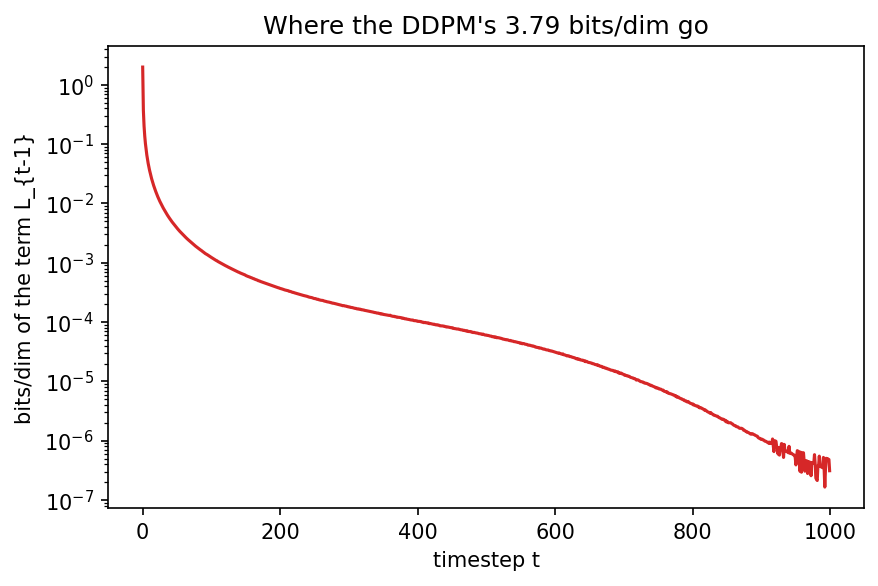

runs/eval/report/fig_by_class_ddpm_ancestral1000.png


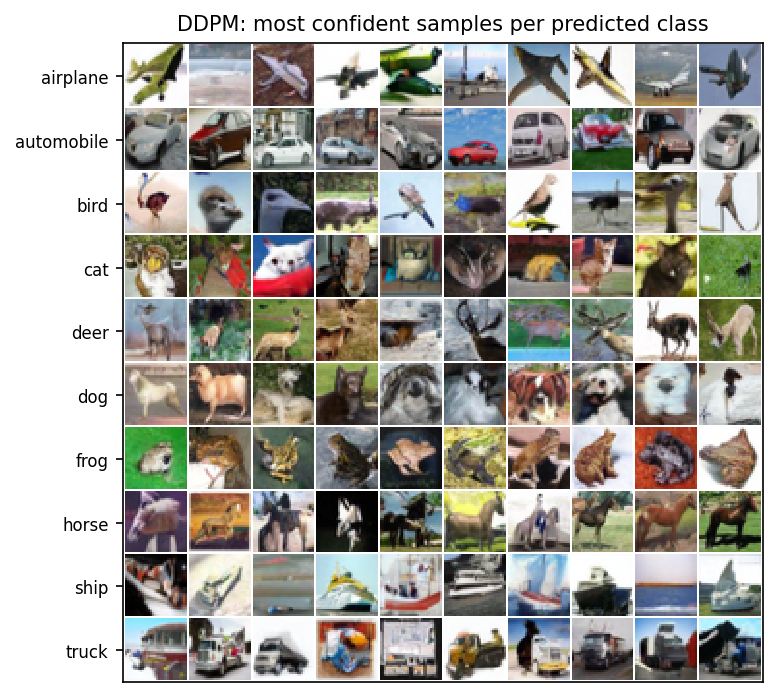

runs/eval/report/fig_by_class_vae_conv.png


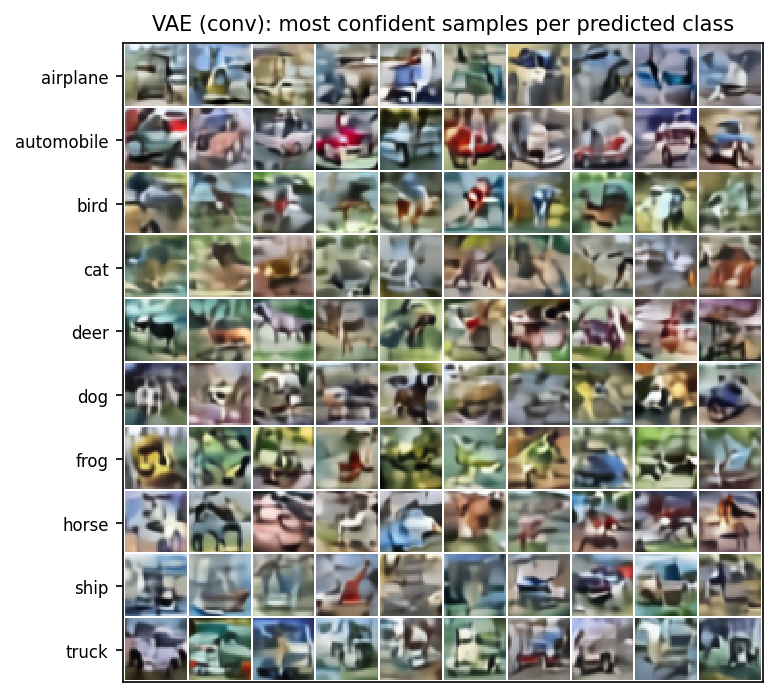

runs/eval/report/fig_class_distribution.png


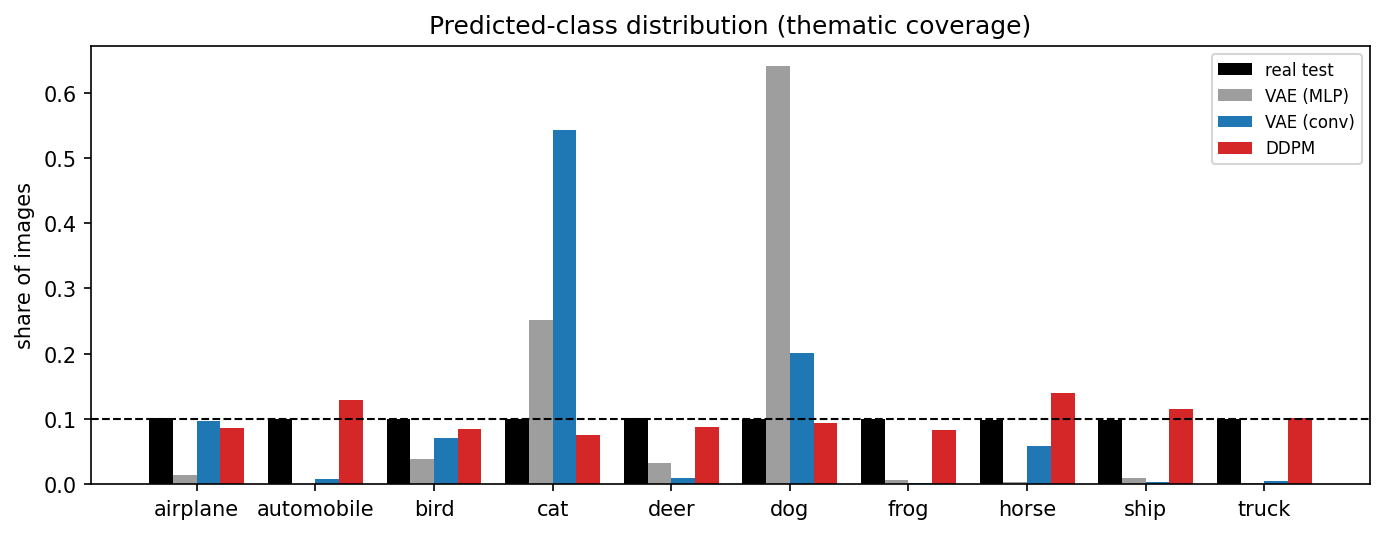

runs/eval/report/fig_ddim_steps.png


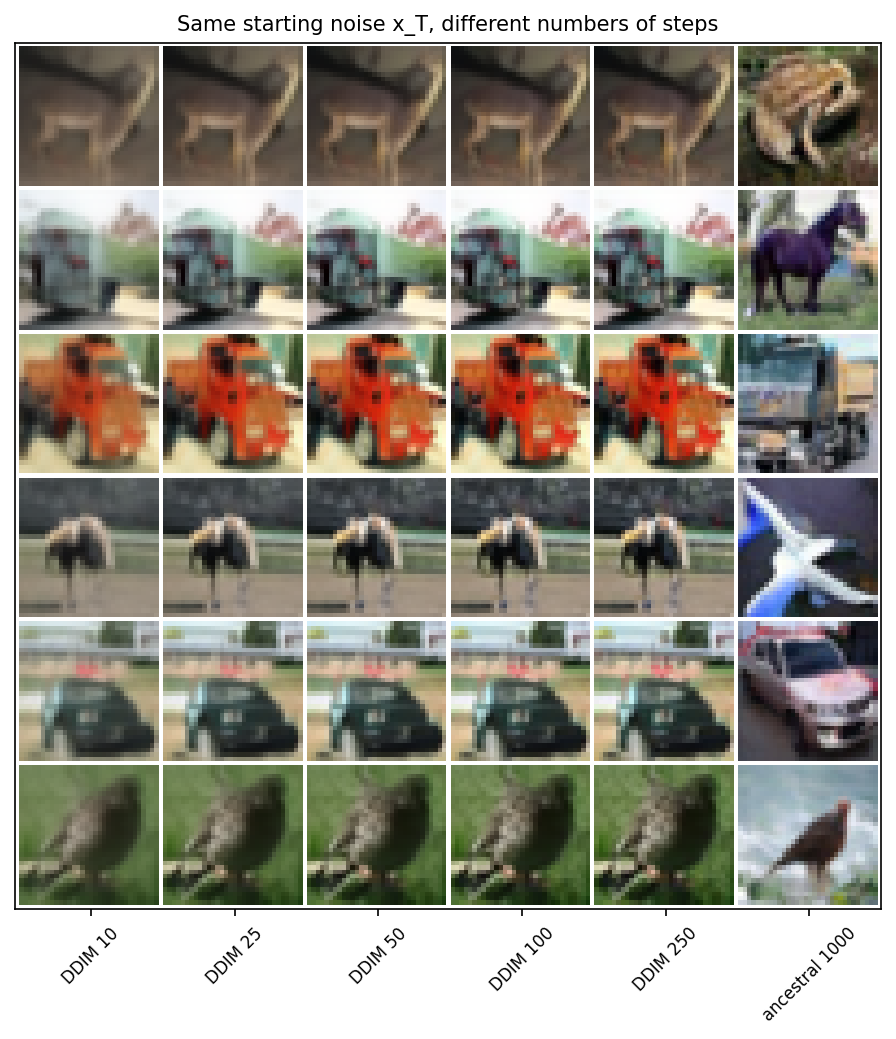

runs/eval/report/fig_ddpm_denoising.png


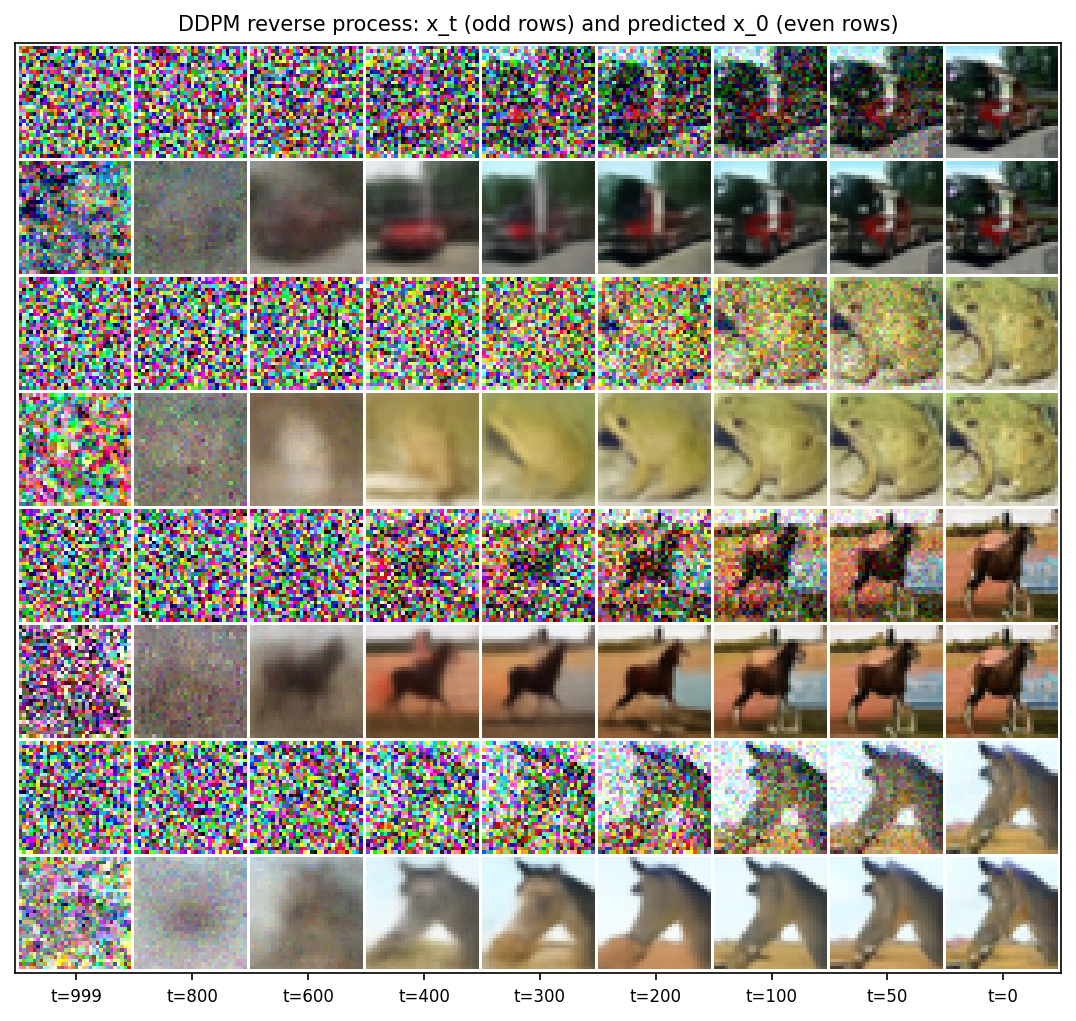

runs/eval/report/fig_failures.png


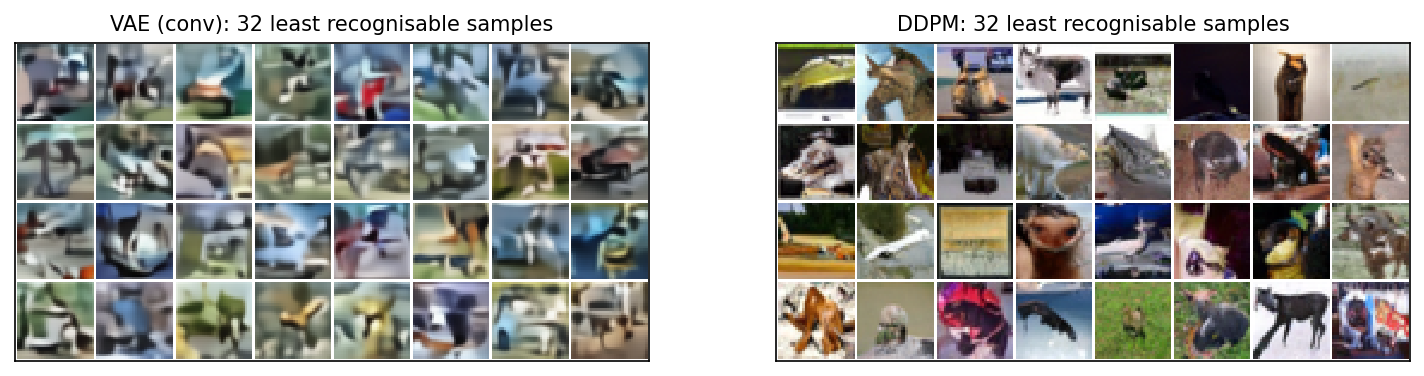

runs/eval/report/fig_fid_during_training.png


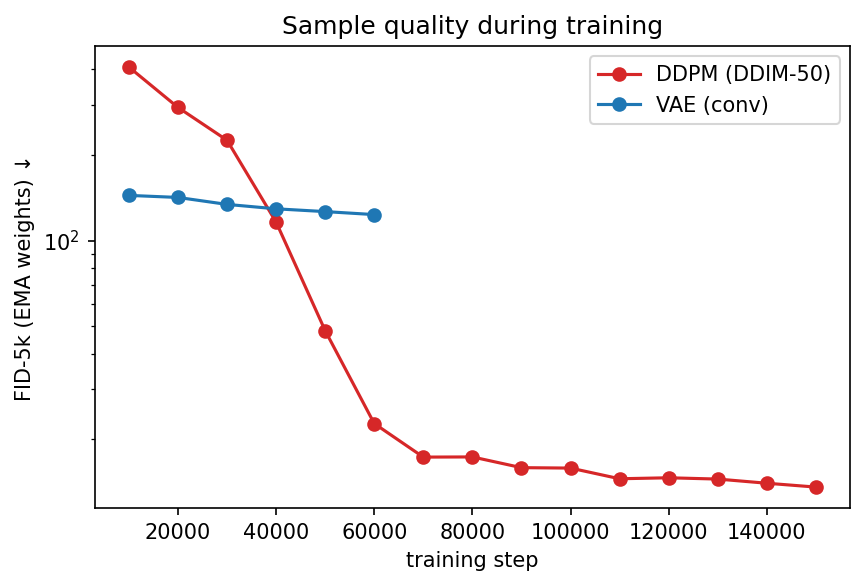

runs/eval/report/fig_interpolation.png


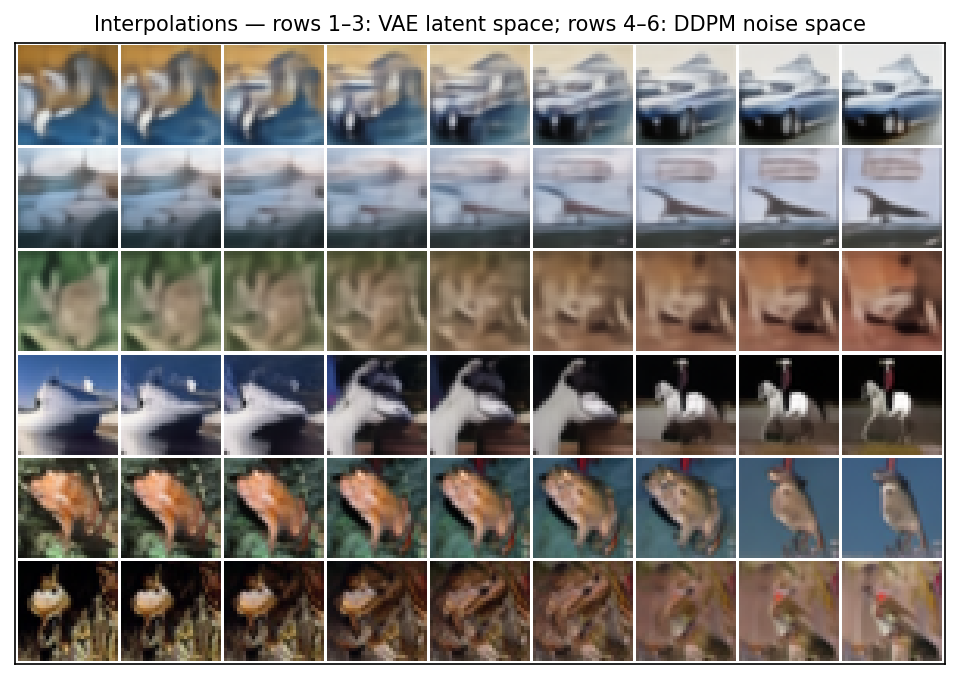

runs/eval/report/fig_nearest_neighbours.png


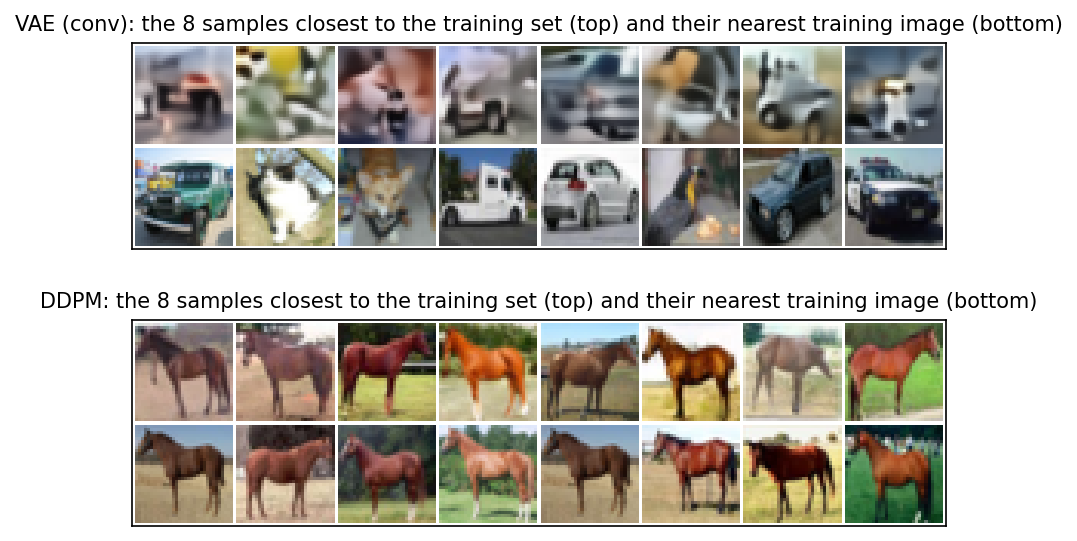

runs/eval/report/fig_precision_recall.png


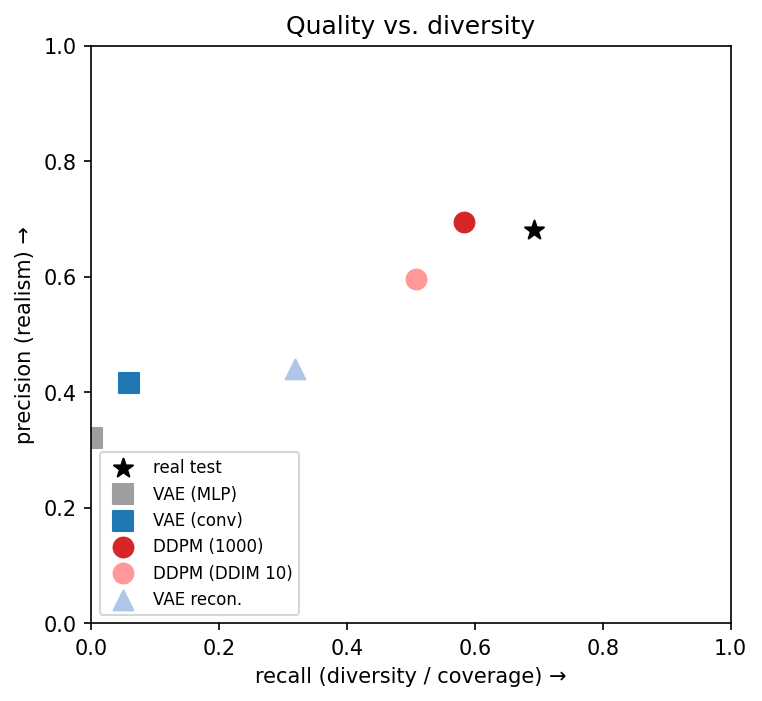

runs/eval/report/fig_samples.png


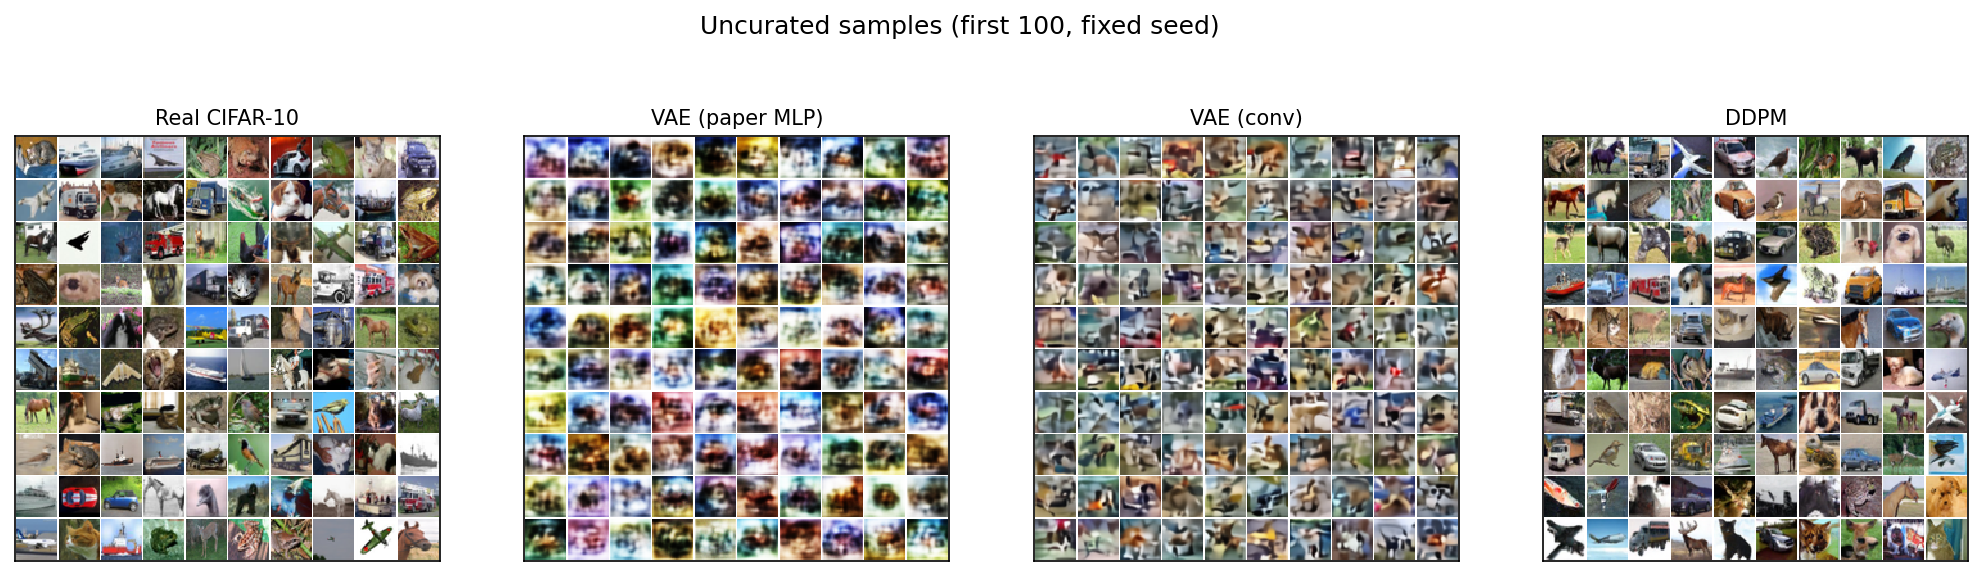

runs/eval/report/fig_speed_quality.png


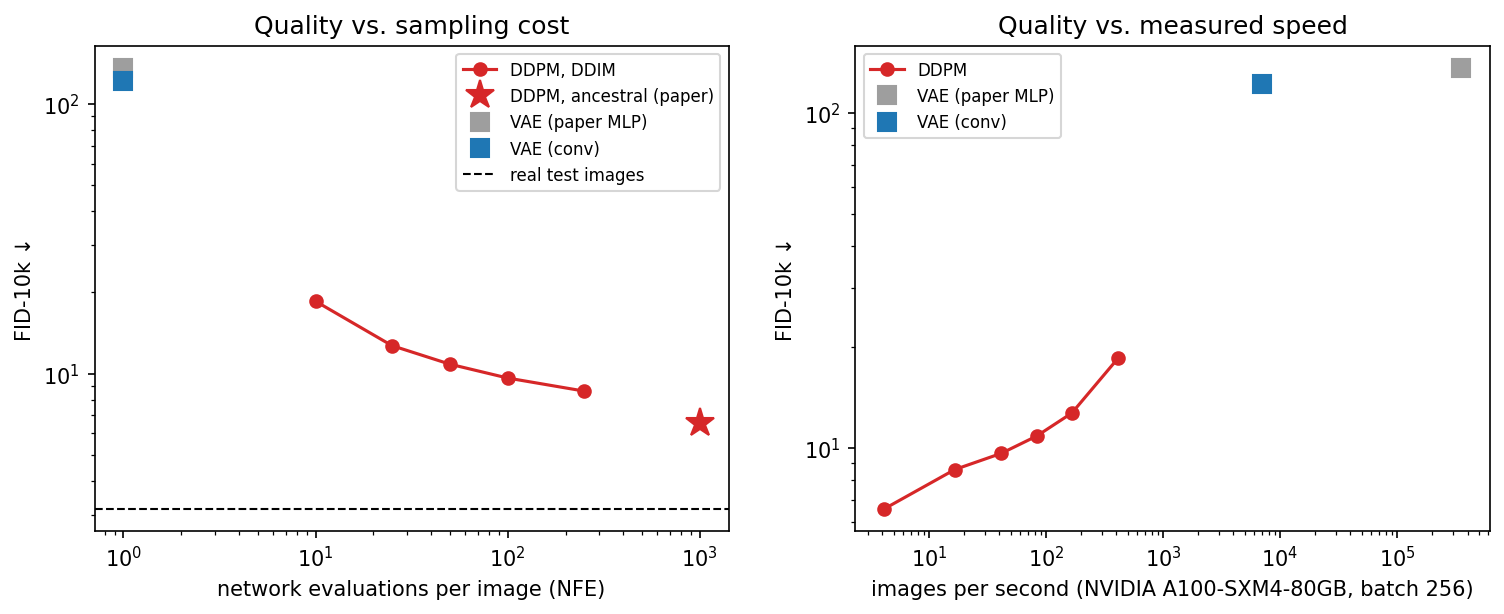

runs/eval/report/fig_vae_reconstructions.png


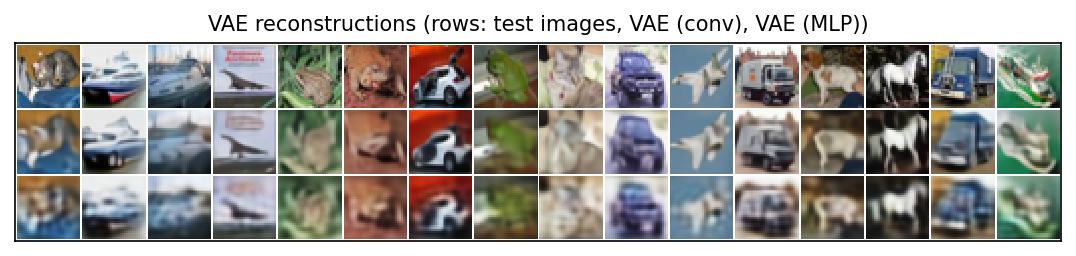

In [4]:
!python scripts/make_figures.py --model-figures

import glob
from IPython.display import Markdown, Image, display
display(Markdown(open('runs/eval/report/results.md').read()))
for f in sorted(glob.glob('runs/eval/report/*.png')):
    print(f); display(Image(f))

## Optional — blind self-rating (≈20 min, no GPU)
150 shuffled images (50 real, 50 VAE, 50 DDPM) are shown one at a time without their source. Rate each one;
answers are saved after every image, so you can stop and continue later. The sources are revealed only at
the end. Afterwards re-run Step 3 to add the results to the report.

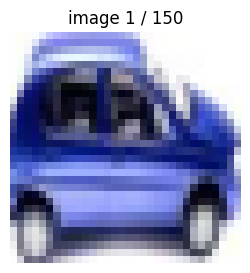

realism 1 (clearly fake) .. 5 (photo-realistic): 2
class? 0=airplane  1=automobile  2=bird  3=cat  4=deer  5=dog  6=frog  7=horse  8=ship  9=truck  -=unrecognisable: 3
real photo or generated? (r/g): g


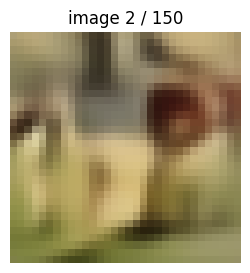

realism 1 (clearly fake) .. 5 (photo-realistic): 1
class? 0=airplane  1=automobile  2=bird  3=cat  4=deer  5=dog  6=frog  7=horse  8=ship  9=truck  -=unrecognisable: -
real photo or generated? (r/g): g


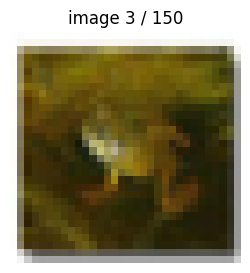

realism 1 (clearly fake) .. 5 (photo-realistic): 1
class? 0=airplane  1=automobile  2=bird  3=cat  4=deer  5=dog  6=frog  7=horse  8=ship  9=truck  -=unrecognisable: 6
real photo or generated? (r/g): g


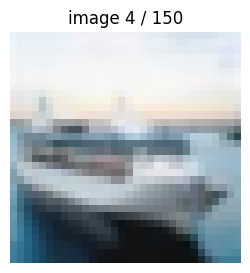

realism 1 (clearly fake) .. 5 (photo-realistic): 1
class? 0=airplane  1=automobile  2=bird  3=cat  4=deer  5=dog  6=frog  7=horse  8=ship  9=truck  -=unrecognisable: -
real photo or generated? (r/g): r


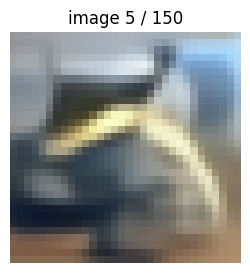

KeyboardInterrupt: Interrupted by user

In [5]:
import sys; sys.path.insert(0, 'scripts')
import blind_rating
if not os.path.exists('runs/eval/blind/set.npz'):
    blind_rating.prepare('runs/eval', per_source=50, data_root='data')
blind_rating.rate('runs/eval')

In [ ]:
blind_rating.score('runs/eval')